# Interview Body-Language Recognition — **Paper-faithful, leakage-free pipeline (v5)**
### Adapted from *Multiview Attention Fusion for Explainable Body Language Behavior Recognition* (Madan et al., IEEE TAFFC 2025)

**What this version does**

| Item | Paper | v5 |
|---|---|---|
| Video Swin | Pretrained Video Swin **fine-tuned** on RGB and (separately) on DCT clips, used as feature extractor, **1024-d** | `swin3d_b` (Swin-B, **1024-d**, Kinetics-400 / ImageNet-22K pretrained), fine-tuned separately on RGB and DCT, then used as feature extractor |
| LaViLa | **Frozen** LaViLa (TimeSformer) on 4 random frames → matrix → **Transformer encoder head** trained | Frozen official LaViLa TimeSformer-B visual encoder (checkpoint auto-downloaded or supplied) → matrix of 256 random-4-frame samples (256×768, as in the paper) → Transformer encoder head |
| Fusion heads | SGD 0.01, 300 epochs, early stopping (patience 5) | Same |
| Skeleton | TAPIR + three-stream transformer | **TAPIR** tracks the 33 MediaPipe first-frame landmarks (paper pipeline) + same three-stream transformer; per-clip fallback to the cached MediaPipe skeleton |
| Multiview attention | 3 cameras | **Not possible** (1 view) |

**How overfitting is controlled (and how *all* clips get used):**
- **Subject-grouped, stratified K-fold cross-validation.** Every clip is used for training in K−1 folds and is tested exactly once, in a fold where **its subject was never seen**. The reported score is the pooled *out-of-fold* accuracy / mAP, so it comes from all clips and no clip is ever scored by a model that trained on it.
- Swin fine-tuning uses a **fixed** number of epochs with small LR, weight decay, label smoothing, dropout and augmentation — no test-fold information is used to pick anything.
- Fusion heads use heavy dropout / weight decay, augmented feature views, and early stopping on an **inner** split of the training folds only.
- An explicit **train-vs-held-out gap table** shows how much each model overfits.
- Finally a **final model is trained on all clips** (fixed epochs chosen from CV). Its true accuracy is the CV estimate — there is nothing left to test it on, and reporting its training accuracy as "accuracy" would be misleading.

**Honest limits:** A few hundred clips at most (and, unless you supply real person IDs, mostly one clip per 'subject') gives high-variance estimates; differences of 1-3 accuracy points are within noise. The paper's BBSI numbers (trimodal val MAP 0.52 / test 0.62; multilabel, 3 views, 2.87M frames) are **not directly comparable** to a single-view, single-label run on your clips, and no code can guarantee beating them.

**Evaluation metrics (exactly as defined in the paper, §IV-B "Performance Metrics")**

| Task | Paper metric | How it is computed here |
|---|---|---|
| Multiclass (this notebook's single-label, softmax setup) | **Mean per-class accuracy** = mean of the top-1 recognition rate of each category | `mean_per_class_acc` on the pooled out-of-fold predictions (per-class recall, averaged with equal weight per class) |
| Multilabel / class imbalance | **MAP** = per-class average precision, **macro-averaged** (equal weight for every class) | `macro_map` = one-vs-rest `average_precision_score` per class, averaged over classes |

Plain overall (micro) accuracy is still printed, but only as a *reference* column — it is **not** the paper's metric and is dominated by the large classes.


## 0. Setup

In [1]:
import os, sys, subprocess, glob, json, random, time, re, zipfile, copy, math, tempfile, warnings
warnings.filterwarnings("ignore")

def pip_install(pkgs):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    if r.returncode != 0:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--break-system-packages", *pkgs])

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:
    pip_install(["torch"])
    import torch
    import torch.nn as nn
    import torch.nn.functional as F

try:
    import torchvision
except ImportError:
    pip_install(["torchvision"])
    import torchvision

try:
    from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
    from sklearn.metrics import confusion_matrix, classification_report, average_precision_score
except ImportError:
    pip_install(["scikit-learn"])
    from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
    from sklearn.metrics import confusion_matrix, classification_report, average_precision_score

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("work")
os.makedirs(WORK_DIR, exist_ok=True)

# ============================ CONFIG ============================================================
ALLOW_SYNTHETIC_DEMO = False   # False: stop with a clear message if your dataset is not attached.
                               # True : run on synthetic data (pipeline smoke test; results meaningless).

BACKBONE_ARCH = "swin3d_b"     # Swin-B -> 1024-d features, as in the paper ("swin3d_t" = 768-d, lighter)
N_BACKBONE_FRAMES = 32         # frames per clip fed to Video Swin (paper: 32-frame videos)
BACKBONE_SIZE = 224
FEATURE_BATCH = 4              # clips per forward pass during feature extraction

N_FOLDS = 5                    # subject-grouped stratified K-fold (every clip is trained on AND tested once)

FINETUNE_BACKBONE = True       # fine-tune Video Swin on RGB and DCT separately (paper)
FT_UNFREEZE = "last_stage"     # "head_only" | "last_stage" | "last_two_stages" | "all"
FT_EPOCHS = 10                 # fixed (no test-fold information used to choose it)
FT_BATCH = 2
FT_LR_BACKBONE, FT_LR_HEAD = 2e-5, 1e-3
FT_WEIGHT_DECAY, FT_LABEL_SMOOTH = 0.05, 0.1
N_AUG_VIEWS = 3                # extra augmented feature views per training clip (augmentation for the heads)

PAPER_OPTIMIZER = True         # SGD lr 0.01 (+momentum 0.9) for fusion heads; Adam 1e-3 for LaViLa head
HEAD_EPOCHS, HEAD_PATIENCE = 300, 5
HEAD_MIN_EPOCHS = 20           # early stopping cannot trigger before this (inner-val loss is noisy on tiny sets)
HEAD_DROPOUT, HEAD_INPUT_DROPOUT = 0.5, 0.3
SKEL_NOISE = 0.05              # gaussian noise (in standardised units) added to skeleton inputs while training
FIXED_HEAD_EPOCHS = 60         # only used if an inner early-stopping split is impossible

REPORT_VARIANT = "Quadmodal (RGB+DCT+Skel+LaViLa)"   # variant used for the confusion matrix / per-class report / final all-clips model.
                                                      # None = automatically use the top-ranked variant of the results table.
FINAL_FIT_ALL = True           # after CV, train the deployable model on ALL clips

EXPECTED_CLIPS = 200           # number of clips in your preprocessing run (200 now); used to pick the right preprocessed dataset and to sanity-check it
# ================================================================================================

print(f"torch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " -- no GPU found, this will be very slow"))
print(f"WORK_DIR: {WORK_DIR}")
print("Setup OK.")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128
Device: cuda (Tesla T4)
WORK_DIR: /kaggle/working
Setup OK.


## 0b. Video Swin backbone (Swin-B, 1024-d)

Order tried: `swin3d_b` (Kinetics-400 + ImageNet-22K) → `swin3d_b` (Kinetics-400) → `swin3d_t` (768-d) → `r3d_18` →
`swin3d_b` with random weights (only if no pretrained weights can be downloaded; printed loudly). A pristine CPU copy is
kept and cloned for every fold so folds never share fine-tuned weights.

In [2]:
def build_video_backbone(arch=None):
    """Returns (backbone_module, feature_dim, backbone_name)."""
    from torchvision.models import video as tvv
    arch = arch or BACKBONE_ARCH
    tries = []
    if arch == "swin3d_b":
        tries += [("swin3d_b", "KINETICS400_IMAGENET22K_V1"), ("swin3d_b", "KINETICS400_V1")]
    tries += [("swin3d_t", "KINETICS400_V1")]
    wcls = {"swin3d_b": "Swin3D_B_Weights", "swin3d_t": "Swin3D_T_Weights"}
    for name, wname in tries:
        try:
            m = getattr(tvv, name)(weights=getattr(getattr(tvv, wcls[name]), wname))
            dim = m.head.in_features
            m.head = nn.Identity()
            tag = f"{name} ({wname})"
            if name != arch:
                print(f"!! FALLBACK backbone in use: {tag}")
            else:
                print(f"Loaded {tag}, feature dim {dim}.")
            return m, dim, tag
        except Exception as e:
            print(f"Could not load {name}/{wname}: {e!r}")
    try:
        m = tvv.r3d_18(weights=tvv.R3D_18_Weights.KINETICS400_V1)
        m.fc = nn.Identity()
        print("!! FALLBACK: R3D-18 (Kinetics-400).")
        return m, 512, "r3d_18"
    except Exception as e:
        print(f"Could not load r3d_18 either: {e!r}")
    m = tvv.swin3d_b(weights=None)
    dim = m.head.in_features
    m.head = nn.Identity()
    print("!! WARNING: no pretrained weights could be downloaded (Internet off?). Using RANDOM swin3d_b -- "
          "features will NOT be meaningful. Turn Internet ON in the notebook settings.")
    return m, dim, "swin3d_b (random init)"

BACKBONE_BASE, BACKBONE_DIM, BACKBONE_NAME = build_video_backbone()
BACKBONE_BASE = BACKBONE_BASE.cpu().eval()
for _p in BACKBONE_BASE.parameters():
    _p.requires_grad = False

def fresh_backbone():
    return copy.deepcopy(BACKBONE_BASE)

print(f"Backbone: {BACKBONE_NAME} | feature dim = {BACKBONE_DIM}")

Downloading: "https://download.pytorch.org/models/swin3d_b_22k-7c6ae6fa.pth" to /root/.cache/torch/hub/checkpoints/swin3d_b_22k-7c6ae6fa.pth


100%|██████████| 364M/364M [00:01<00:00, 213MB/s]


Loaded swin3d_b (KINETICS400_IMAGENET22K_V1), feature dim 1024.
Backbone: swin3d_b (KINETICS400_IMAGENET22K_V1) | feature dim = 1024


## 0c. LaViLa (frozen) — how to set the checkpoint

The paper uses LaViLa **frozen** as a feature extractor (no fine-tuning) and trains a Transformer encoder head on its
features. This cell loads the **official LaViLa TimeSformer-B visual encoder** (the dual-encoder checkpoint pretrained on
Ego4D). It downloads only two small source files from the LaViLa GitHub repo (no full clone, no GPT-2 / transformers
dependencies), and the checkpoint itself.

**Option A — automatic (easiest):** Kaggle notebook *Settings → Internet ON*, keep `LAVILA_AUTO_DOWNLOAD = True`.
The checkpoint (a large file — the download can take several minutes) is fetched from Meta's server to `/kaggle/temp`
(not saved in your notebook output).

**Option B — manual:** download the `.pth` from the URL below on your PC → Kaggle → *Datasets → New Dataset* → upload it →
in the notebook *Add Input* → that dataset → set
`LAVILA_CHECKPOINT_PATH = "/kaggle/input/<your-dataset-slug>/clip_openai_timesformer_base.narrator_rephraser.ep_0005.md5sum_d73a9c.pth"`.
(If left `None`, any `*timesformer*.pth` under `/kaggle/input` is picked up automatically.)

If anything fails, LaViLa is skipped with the exact reason printed and everything else runs unchanged.

In [3]:
LAVILA_CHECKPOINT_PATH = None      # <- Option B: path to your uploaded checkpoint (else auto-detect / auto-download)
LAVILA_AUTO_DOWNLOAD = True        # <- Option A: needs Internet ON
LAVILA_N_SAMPLES = 256             # random 4-frame draws per clip -> (256 x 768) feature matrix, as in the paper
LAVILA_CKPT_URL = ("https://dl.fbaipublicfiles.com/lavila/checkpoints/dual_encoders/ego4d/"
                   "clip_openai_timesformer_base.narrator_rephraser.ep_0005.md5sum_d73a9c.pth")
LAVILA_RAW = "https://raw.githubusercontent.com/facebookresearch/LaViLa/main/"
LAVILA_MEAN = torch.tensor([108.3272985, 116.7460125, 104.09373615]) / 255.0   # LaViLa (OpenAI-CLIP TSF) stats
LAVILA_STD  = torch.tensor([68.5005327, 66.6321579, 70.32316305]) / 255.0
LAVILA_TMP = "/kaggle/temp" if os.path.isdir("/kaggle/temp") else tempfile.gettempdir()
LAVILA_SRC_DIR = os.path.join(LAVILA_TMP, "lavila_src")

def _download(url, dest):
    import urllib.request
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    state = {"last": -10}
    def hook(bn, bs, total):
        if total > 0:
            pct = int(100 * bn * bs / total)
            if pct >= state["last"] + 10:
                state["last"] = pct
                print(f"    {min(pct, 100)}% of {total / 1e6:.0f} MB")
    urllib.request.urlretrieve(url, dest + ".part", hook)
    os.replace(dest + ".part", dest)

def _ensure_lavila_sources():
    for rel in ("lavila/models/timesformer.py", "lavila/models/openai_model.py"):
        dest = os.path.join(LAVILA_SRC_DIR, rel)
        if not os.path.isfile(dest):
            _download(LAVILA_RAW + rel, dest)
    if LAVILA_SRC_DIR not in sys.path:
        sys.path.insert(0, LAVILA_SRC_DIR)

def _ensure_timm():
    try:
        import timm, einops  # noqa: F401
    except ImportError:
        pip_install(["timm", "einops"])
    try:
        from timm.models.layers import DropPath, to_2tuple, trunc_normal_  # noqa: F401
    except Exception:                       # newer timm removed the old path: provide a small shim
        import types, timm.layers as tl
        shim = types.ModuleType("timm.models.layers")
        shim.DropPath, shim.to_2tuple, shim.trunc_normal_ = tl.DropPath, tl.to_2tuple, tl.trunc_normal_
        sys.modules["timm.models.layers"] = shim

def try_setup_lavila():
    """Returns the frozen LaViLa visual encoder (input (B,3,4,224,224) -> (B,768)) or None. Never raises."""
    try:
        path = LAVILA_CHECKPOINT_PATH
        if path is None:
            found = sorted(glob.glob("/kaggle/input/**/*timesformer*.pth", recursive=True))
            if found:
                path = found[0]
                print(f"Found a LaViLa checkpoint in your inputs: {path}")
        if path is None or not os.path.isfile(str(path)):
            if not LAVILA_AUTO_DOWNLOAD:
                print("No LaViLa checkpoint (LAVILA_CHECKPOINT_PATH unset, auto-download off) -- skipping LaViLa.")
                return None
            path = os.path.join(LAVILA_TMP, os.path.basename(LAVILA_CKPT_URL))
            if not os.path.isfile(path):
                print(f"Downloading LaViLa checkpoint -> {path}")
                _download(LAVILA_CKPT_URL, path)
        _ensure_timm()
        _ensure_lavila_sources()
        from lavila.models.timesformer import SpaceTimeTransformer
        from lavila.models.openai_model import QuickGELU
        vis = SpaceTimeTransformer(num_frames=4, time_init="zeros", attention_style="frozen-in-time",
                                   ln_pre=True, act_layer=QuickGELU, is_tanh_gating=False, drop_path_rate=0.0)
        vis.head, vis.pre_logits, vis.fc = nn.Identity(), nn.Identity(), nn.Identity()
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
        sd_all = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
        sd = {}
        for k, v in sd_all.items():
            k = k.replace("module.", "")
            if k.startswith("visual."):
                sd[k[len("visual."):]] = v
        del ckpt, sd_all
        res = vis.load_state_dict(sd, strict=False)
        if len(sd) == 0 or len(res.missing_keys) > 0:
            print(f"LaViLa weights did not match the visual encoder (missing: {res.missing_keys[:5]}, "
                  f"loaded tensors: {len(sd)}) -- skipping LaViLa.")
            return None
        vis = vis.to(DEVICE).eval()
        for p in vis.parameters():
            p.requires_grad = False
        with torch.no_grad():
            out = vis(torch.zeros(1, 3, 4, 224, 224, device=DEVICE))
        if out.ndim != 2 or out.shape[1] != 768:
            print(f"Unexpected LaViLa output shape {tuple(out.shape)} -- skipping LaViLa.")
            return None
        print(f"LaViLa visual encoder ready (frozen); probe output {tuple(out.shape)}.")
        return vis
    except Exception as e:
        print(f"LaViLa setup failed ({e!r}) -- skipping the LaViLa branch. "
              "(Internet off? Then use Option B, or set LAVILA_AUTO_DOWNLOAD=False to silence this.)")
        return None

try:
    LAVILA_VISUAL = try_setup_lavila()
except Exception as e:
    print(f"Unexpected LaViLa error ({e!r}); treating LaViLa as unavailable.")
    LAVILA_VISUAL = None
LAVILA_AVAILABLE = LAVILA_VISUAL is not None
print(f"\nLAVILA_AVAILABLE = {LAVILA_AVAILABLE}")
if not LAVILA_AVAILABLE:
    print("Continuing without LaViLa -- RGB, DCT and Skeleton branches are unaffected.")

    0% of 711 MB
    10% of 711 MB
    20% of 711 MB
    30% of 711 MB
    40% of 711 MB
    50% of 711 MB
    60% of 711 MB
    70% of 711 MB
    80% of 711 MB
    90% of 711 MB
    100% of 711 MB
    0% of 0 MB
    48% of 0 MB
    97% of 0 MB
    100% of 0 MB
    0% of 0 MB
    42% of 0 MB
    84% of 0 MB
    100% of 0 MB
######USING ATTENTION STYLE:  frozen-in-time
LaViLa visual encoder ready (frozen); probe output (1, 768).

LAVILA_AVAILABLE = True


## 1. Locate the preprocessing notebook's output (`annotations.csv` + `cache/*.pt`)

Search order: `/kaggle/working`, `/kaggle/input`, `/mnt/user-data/uploads`. **Every** preprocessed dataset found is listed; the one whose `annotations.csv` has exactly `EXPECTED_CLIPS` rows is used (so an old 100/140-clip dataset that is still attached is never picked by mistake). If none matches, the newest-looking one is used and a loud warning is printed. If only `preprocessed_dataset.zip`
is found it is extracted automatically. If nothing is found, see the printed instructions.

**To use your real data on Kaggle:** *Add Input → Upload / Your Datasets →* the `preprocessed_dataset.zip`
produced by the preprocessing notebook (or run that notebook first in the same session), then re-run.

If nothing is found the notebook stops with instructions (set `ALLOW_SYNTHETIC_DEMO = True` only for a pipeline smoke test).

In [4]:
CANDIDATE_ROOTS = ["/kaggle/working", "/kaggle/input", "/mnt/user-data/uploads"]   # /kaggle/input is searched recursively, so any attached dataset is found
SYNTH_DIRNAME = "synthetic_demo_data"

def _cache_dir_for(ann_path):
    base = os.path.dirname(ann_path)
    for cand in (os.path.join(base, "cache"), base):
        if os.path.isdir(cand) and glob.glob(os.path.join(cand, "*.pt")):
            return cand
    return None

def find_preprocessed_data(include_synthetic=False):
    """Collect EVERY (annotations.csv, cache dir) pair, then choose the one that matches EXPECTED_CLIPS."""
    cands, seen = [], set()
    for root in CANDIDATE_ROOTS:
        if not os.path.isdir(root):
            continue
        for ann_path in sorted(glob.glob(os.path.join(root, "**", "annotations.csv"), recursive=True)):
            if (SYNTH_DIRNAME in ann_path) and not include_synthetic:
                continue
            real = os.path.realpath(ann_path)
            if real in seen:
                continue
            seen.add(real)
            cache_dir = _cache_dir_for(ann_path)
            if cache_dir is None:
                continue
            try:
                n_rows = len(pd.read_csv(ann_path, usecols=["clip_id"]))
            except Exception:
                n_rows = -1
            n_pt = len(glob.glob(os.path.join(cache_dir, "*.pt")))
            cands.append({"ann": ann_path, "cache": cache_dir, "rows": n_rows, "pt": n_pt})
    if not cands:
        return None, None
    print("Preprocessed datasets found:")
    for c in cands:
        print(f"  rows={c['rows']:4d}  cache_files={c['pt']:4d}   {c['ann']}")
    exact = [c for c in cands if c["rows"] == EXPECTED_CLIPS and c["pt"] == EXPECTED_CLIPS]
    exact_rows = [c for c in cands if c["rows"] == EXPECTED_CLIPS]
    if exact:
        pick = exact[0]
    elif exact_rows:
        pick = exact_rows[0]
        print(f"WARNING: annotations.csv has {EXPECTED_CLIPS} rows but only {pick['pt']} cache files were found.")
    else:
        pick = max(cands, key=lambda c: c["rows"])
        print(f"WARNING: no preprocessed dataset has exactly EXPECTED_CLIPS={EXPECTED_CLIPS} rows. "
              f"Using the largest one ({pick['rows']} rows). If that is not what you want, attach the right "
              f"dataset (or change EXPECTED_CLIPS in the config cell).")
    if len(cands) > 1:
        print(f"-> using: {pick['ann']}   (ignoring {len(cands) - 1} other preprocessed dataset(s))")
    return pick["ann"], pick["cache"]

def try_extract_zip():
    for root in CANDIDATE_ROOTS:
        if not os.path.isdir(root):
            continue
        for z in sorted(glob.glob(os.path.join(root, "**", "*.zip"), recursive=True)):
            if "preprocess" not in os.path.basename(z).lower():
                continue
            out = os.path.join(WORK_DIR, "preprocessed_extracted")
            try:
                print(f"No extracted preprocessed data found; extracting {z} -> {out}")
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(out)
                return True
            except Exception as e:
                print(f"  could not extract ({e!r})")
    return False

ANNOTATIONS_PATH, CACHE_DIR = find_preprocessed_data()
if ANNOTATIONS_PATH is None and try_extract_zip():
    CANDIDATE_ROOTS.append(os.path.join(WORK_DIR, "preprocessed_extracted"))
    ANNOTATIONS_PATH, CACHE_DIR = find_preprocessed_data()

USING_SYNTHETIC = False
if ANNOTATIONS_PATH is None:
    msg = ("\n" + "=" * 92 +
           "\nNO PREPROCESSED DATA FOUND under " + str(CANDIDATE_ROOTS) +
           "\nAttach the preprocessing notebook's output: Kaggle -> Add Input -> your dataset containing"
           "\npreprocessed_dataset.zip (annotations.csv + cache/*.pt), or run the preprocessing notebook first in"
           "\nthis same session, then re-run this notebook." +
           "\n" + "=" * 92)
    print(msg)
    if not ALLOW_SYNTHETIC_DEMO:
        raise SystemExit("Stopped: no data (ALLOW_SYNTHETIC_DEMO is False).")
    USING_SYNTHETIC = True
    print("\n>>> Falling back to a SYNTHETIC smoke-test dataset so every cell can be verified end-to-end.")
    print(">>> All numbers below are MEANINGLESS for your project until real data is attached.\n")

    synth_root = os.path.join(WORK_DIR, SYNTH_DIRNAME)
    os.makedirs(os.path.join(synth_root, "cache"), exist_ok=True)
    rng = np.random.RandomState(SEED)
    syn_classes = ["neutral", "engaged", "fidgeting", "closed"]
    n_subjects, rows, cid = 12, [], 0
    for s in range(n_subjects):
        for k, cname in enumerate(syn_classes):
            t = np.linspace(0, 1, 64)[:, None, None]
            base = 0.15 + 0.2 * k
            stripe = (np.sin(2 * np.pi * (k + 1) * (t + np.linspace(0, 1, 64)[None, None, :])) + 1) / 2
            vid = base + 0.4 * np.broadcast_to(stripe, (64, 64, 64)) + 0.1 * rng.randn(64, 64, 64)
            vid = np.clip(vid, 0, 1)[..., None].repeat(3, axis=-1)
            frames = torch.from_numpy((vid * 255).astype(np.uint8))                      # (T, H, W, 3)
            dct = torch.from_numpy((np.clip(vid[..., ::-1] * 0.9, 0, 1) * 255).astype(np.uint8))
            ph = np.linspace(0, 2 * np.pi * (k + 1), 64)[:, None, None]
            P = 0.5 + 0.05 * (k + 1) * np.sin(ph + rng.rand(1, 33, 2) * 6) + 0.01 * rng.randn(64, 33, 2)
            Tt = np.diff(P, axis=0)
            S = 0.1 * (k + 1) * rng.rand(64, 31, 2) + 0.05 * np.sin(ph) + 0.01 * rng.randn(64, 31, 2)
            torch.save({"frames": frames, "dct_frames": dct,
                        "P": torch.tensor(P, dtype=torch.float32), "T": torch.tensor(Tt, dtype=torch.float32),
                        "S": torch.tensor(S, dtype=torch.float32), "label": k},
                       os.path.join(synth_root, "cache", f"clip_{cid:03d}.pt"))
            rows.append({"clip_id": cid, "class_id": k, "class_name": cname, "subject_id": f"S{s:02d}"})
            cid += 1
    pd.DataFrame(rows).to_csv(os.path.join(synth_root, "annotations.csv"), index=False)
    ANNOTATIONS_PATH, CACHE_DIR = os.path.join(synth_root, "annotations.csv"), os.path.join(synth_root, "cache")

print(f"annotations.csv -> {ANNOTATIONS_PATH}")
print(f"cache/*.pt      -> {CACHE_DIR}  ({len(glob.glob(os.path.join(CACHE_DIR, '*.pt')))} files)")
DATA_TAG = "SYNTHETIC" if USING_SYNTHETIC else "REAL"

annotations = pd.read_csv(ANNOTATIONS_PATH)
required = {"clip_id", "class_name"}
missing_cols = required - set(annotations.columns)
if missing_cols:
    raise ValueError(f"annotations.csv is missing required column(s) {sorted(missing_cols)}; found {list(annotations.columns)}")

if not USING_SYNTHETIC:
    _avail = set()
    for _f in glob.glob(os.path.join(CACHE_DIR, "*.pt")):
        _dg = re.findall(r"\d+", os.path.splitext(os.path.basename(_f))[0])
        if _dg:
            _avail.add(int(_dg[-1]))
    _no_cache = annotations[~annotations.clip_id.isin(_avail)]
    if len(_no_cache):
        _names = (_no_cache["original_filename"].tolist() if "original_filename" in _no_cache.columns
                  else _no_cache["clip_id"].tolist())
        print(f"WARNING: {len(_no_cache)} annotation row(s) have NO cache file (these clips FAILED in preprocessing) "
              f"-> excluded from training/testing: {_names[:15]}{' ...' if len(_names) > 15 else ''}")
        annotations = annotations[annotations.clip_id.isin(_avail)].reset_index(drop=True)

if "class_id" in annotations.columns:
    CLASSES = sorted(annotations.class_name.unique(), key=lambda c: annotations.loc[annotations.class_name == c, "class_id"].iloc[0])
else:
    CLASSES = sorted(annotations.class_name.unique())
CLASS2IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
annotations["label_idx"] = annotations.class_name.map(CLASS2IDX).astype(int)
print(f"\n[{DATA_TAG} DATA] {len(annotations)} labelled clips across {NUM_CLASSES} classes.")
if not USING_SYNTHETIC:
    _n_pt = len(glob.glob(os.path.join(CACHE_DIR, "*.pt")))
    if len(annotations) == EXPECTED_CLIPS:
        print(f"OK: all {EXPECTED_CLIPS} expected clips are available for training/testing ({_n_pt} cache files).")
    else:
        print(f"WARNING: expected {EXPECTED_CLIPS} clips but only {len(annotations)} are usable "
              f"({_n_pt} cache files). Check the preprocessing notebook's FAILED list.")
    if "subject_id" in annotations.columns:
        _ns = annotations.subject_id.astype(str).nunique()
        print(f"Subject groups for cross-validation: {_ns} for {len(annotations)} clips.")
        if _ns > 0.8 * len(annotations):
            print("NOTE: almost every clip is its own 'subject', so clips of the SAME person can fall in both "
                  "train and test and the score will look better than it really is. Fix: add a subjects.csv "
                  "(filename,subject_id) to the raw-video dataset and re-run preprocessing.")
display(annotations.head())

Preprocessed datasets found:
  rows= 216  cache_files= 216   /kaggle/input/datasets/anushiyaharssha/preprocessed216videos/annotations.csv
annotations.csv -> /kaggle/input/datasets/anushiyaharssha/preprocessed216videos/annotations.csv
cache/*.pt      -> /kaggle/input/datasets/anushiyaharssha/preprocessed216videos/cache  (216 files)

[REAL DATA] 216 labelled clips across 14 classes.
Subject groups for cross-validation: 204 for 216 clips.
NOTE: almost every clip is its own 'subject', so clips of the SAME person can fall in both train and test and the score will look better than it really is. Fix: add a subjects.csv (filename,subject_id) to the raw-video dataset and re-run preprocessing.


,clip_id,original_filename,standardized_filename,subject_id,class_id,class_name,view,raw_num_frames,raw_fps,raw_width,raw_height,rotation_meta,label_idx
0,0,001_adjusting_cloth.mp4,S001_C12_adjust_clothing_T01.mp4,subj001,12,adjust_clothing,front_single_view,64,16.0,224,224,0,11
1,1,001_fumble.mp4,S001_C03_fumble_T01.mp4,subj001,3,fumble,front_single_view,65,8.0,224,224,0,2
2,2,001_neutral.mp4,S001_C01_neutral_T01.mp4,subj001,1,neutral,front_single_view,65,8.0,224,224,0,0
3,3,001_neutral_64f.mp4,S001_C01_neutral_T02.mp4,subj001,1,neutral,front_single_view,64,16.0,224,224,0,0
4,4,002_gesture.mp4,S002_C02_gesture_T01.mp4,subj002,2,gesture,front_single_view,49,8.0,736,496,0,1


## 2. Class distribution

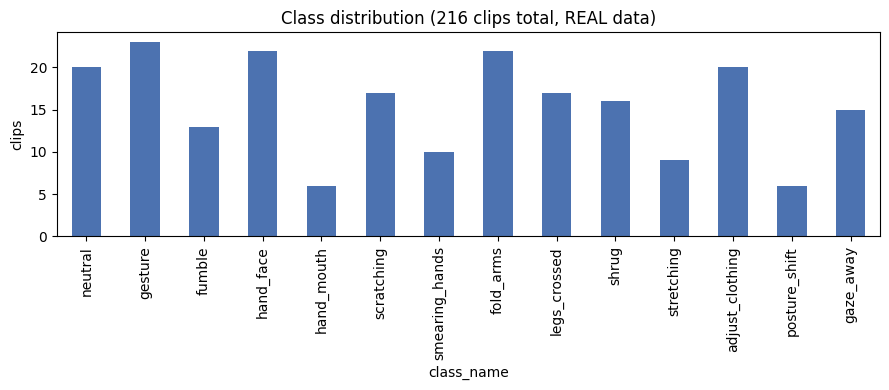

class_name
neutral            20
gesture            23
fumble             13
hand_face          22
hand_mouth          6
scratching         17
smearing_hands     10
fold_arms          22
legs_crossed       17
shrug              16
stretching          9
adjust_clothing    20
posture_shift       6
gaze_away          15


In [5]:
counts = annotations.class_name.value_counts().reindex(CLASSES, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4))
counts.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("clips")
ax.set_title(f"Class distribution ({len(annotations)} clips total, {DATA_TAG} data)")
plt.tight_layout()
plt.show()

print(counts.to_string())
sparse = counts[counts < 3]
if len(sparse):
    print(f"\nCaution: {len(sparse)} class(es) have fewer than 3 examples total -- "
          f"any val-set accuracy for these is not statistically meaningful:")
    print(sparse.to_string())

## 3. Load cached clips (RGB, DCT, skeleton, LaViLa samples)

Videos are stored as fp16 CPU tensors (halves RAM). Frames are uniformly sampled (32), resized to 224 and normalised
with the Kinetics statistics for Swin; LaViLa gets its own random 4-frame samples (256 per clip -> a 256x768 matrix, encoded clip by clip) and normalisation.

In [6]:
KIN_MEAN = torch.tensor([0.4850, 0.4560, 0.4060]).view(1, 3, 1, 1)
KIN_STD  = torch.tensor([0.2290, 0.2240, 0.2250]).view(1, 3, 1, 1)

_cache_files = {}
for _f in glob.glob(os.path.join(CACHE_DIR, "*.pt")):
    _digits = re.findall(r"\d+", os.path.splitext(os.path.basename(_f))[0])
    if _digits:
        _cache_files[int(_digits[-1])] = _f

def cache_path_for(clip_id):
    p = os.path.join(CACHE_DIR, f"clip_{int(clip_id):03d}.pt")
    if os.path.isfile(p):
        return p
    if int(clip_id) in _cache_files:
        return _cache_files[int(clip_id)]
    raise FileNotFoundError(f"No cache file for clip_id={clip_id} in {CACHE_DIR}")

def to_thwc_float(x):
    """Any of (T,H,W,C) / (T,C,H,W), uint8 or float -> float32 (T,H,W,3) in [0,1]."""
    x = torch.as_tensor(x)
    if x.ndim != 4:
        raise ValueError(f"Expected a 4-D frame tensor, got shape {tuple(x.shape)}")
    if x.shape[-1] not in (1, 3) and x.shape[1] in (1, 3):
        x = x.permute(0, 2, 3, 1)
    was_uint8 = x.dtype == torch.uint8
    x = x.float()
    if was_uint8 or x.max() > 1.5:
        x = x / 255.0
    if x.shape[-1] == 1:
        x = x.repeat(1, 1, 1, 3)
    return x.clamp(0, 1)

def prep_video(x, n_frames, size):
    """-> fp16 (1, 3, n_frames, size, size): uniformly sampled, resized, Kinetics-normalised."""
    x = to_thwc_float(x)
    idx = torch.linspace(0, x.shape[0] - 1, n_frames).round().long()
    x = x[idx].permute(0, 3, 1, 2)
    x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    x = (x - KIN_MEAN) / KIN_STD
    return x.permute(1, 0, 2, 3).unsqueeze(0).contiguous().half()

def prep_lavila(x, n_samples, size=224, n_seg=4):
    """-> fp16 (n_samples, 3, 4, size, size): each sample = one random frame from each of 4 equal segments."""
    x = to_thwc_float(x)
    T = x.shape[0]
    bounds = np.linspace(0, T, n_seg + 1).astype(int)
    out = []
    for _ in range(n_samples):
        idx = [random.randint(int(bounds[i]), max(int(bounds[i]), int(bounds[i + 1]) - 1)) for i in range(n_seg)]
        v = x[idx].permute(0, 3, 1, 2)
        v = F.interpolate(v, size=(size, size), mode="bilinear", align_corners=False)
        v = (v - LAVILA_MEAN.view(1, 3, 1, 1)) / LAVILA_STD.view(1, 3, 1, 1)
        out.append(v.permute(1, 0, 2, 3))
    return torch.stack(out).half().contiguous()

@torch.no_grad()
def encode_lavila(frames, n_samples=None, chunk=32, size=224, n_seg=4):
    """Frozen LaViLa: n_samples random 4-frame draws (one random frame per quarter of the clip) -> (n_samples, 768)."""
    n_samples = n_samples or LAVILA_N_SAMPLES
    x = to_thwc_float(frames).permute(0, 3, 1, 2)
    x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    x = (x - LAVILA_MEAN.view(1, 3, 1, 1)) / LAVILA_STD.view(1, 3, 1, 1)
    bounds = np.linspace(0, x.shape[0], n_seg + 1).astype(int)
    out = []
    for s in range(0, n_samples, chunk):
        batch = []
        for _ in range(min(chunk, n_samples - s)):
            idx = [random.randint(int(bounds[i]), max(int(bounds[i]), int(bounds[i + 1]) - 1)) for i in range(n_seg)]
            batch.append(x[idx].permute(1, 0, 2, 3))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            f = LAVILA_VISUAL(torch.stack(batch).to(DEVICE).float())
        out.append(torch.nan_to_num(f.float()).cpu())
    return torch.cat(out)

def skel_to_seq(x):
    x = torch.nan_to_num(torch.as_tensor(x).float(), nan=0.0, posinf=0.0, neginf=0.0)
    if x.ndim < 2:
        raise ValueError(f"Skeleton tensor must be at least 2-D, got {tuple(x.shape)}")
    return x.reshape(x.shape[0], -1)

set_seed(SEED)
t0 = time.time()
rgb_in, dct_in, lav_in = [], [], []
_class_id_of = dict(zip(annotations.clip_id, annotations.class_id)) if "class_id" in annotations.columns else {}
_label_mismatch = []
P_list, T_list, S_list = [], [], []
for n_done, cid in enumerate(annotations.clip_id.tolist(), 1):
    d = torch.load(cache_path_for(cid), map_location="cpu", weights_only=False)
    if (not USING_SYNTHETIC) and cid in _class_id_of and "label" in d:
        if int(d["label"]) != int(_class_id_of[cid]) - 1:      # cache says a different class than annotations.csv
            _label_mismatch.append(cid)
    rgb_in.append(prep_video(d["frames"], N_BACKBONE_FRAMES, BACKBONE_SIZE))
    dct_in.append(prep_video(d["dct_frames"], N_BACKBONE_FRAMES, BACKBONE_SIZE))
    if LAVILA_AVAILABLE:
        try:
            lav_in.append(encode_lavila(d["frames"]))
        except Exception as e:
            print(f"LaViLa feature extraction failed ({e!r}) -- disabling the LaViLa branch.")
            LAVILA_AVAILABLE, lav_in = False, []
    P_list.append(skel_to_seq(d["P"])); T_list.append(skel_to_seq(d["T"])); S_list.append(skel_to_seq(d["S"]))
    if n_done % 20 == 0 or n_done == len(annotations):
        print(f"  loaded {n_done}/{len(annotations)} clips")

if _label_mismatch:
    raise RuntimeError(
        f"{len(_label_mismatch)} cached clip(s) carry a different class label than annotations.csv "
        f"(first clip_ids: {_label_mismatch[:10]}). annotations.csv and cache/*.pt come from DIFFERENT "
        "preprocessing runs (e.g. an old cache next to a new annotations file). Use the annotations.csv and "
        "cache/ from the SAME preprocessed_dataset.zip, then re-run.")
print("Consistency check passed: every cached clip's label matches annotations.csv.")

def stack_streams(lst, name):
    L = min(x.shape[0] for x in lst)
    dims = {x.shape[1] for x in lst}
    if len(dims) != 1:
        raise ValueError(f"Skeleton stream {name} has inconsistent feature widths across clips: {dims}")
    return torch.stack([x[:L] for x in lst])

SKEL_P, SKEL_T, SKEL_S = stack_streams(P_list, "P"), stack_streams(T_list, "T"), stack_streams(S_list, "S")
del P_list, T_list, S_list
N = len(annotations)
LABELS = torch.tensor(annotations.label_idx.values, dtype=torch.long)
print(f"Loaded {N} clips in {time.time() - t0:.1f}s | skeleton P/T/S {tuple(SKEL_P.shape)} / {tuple(SKEL_T.shape)} / {tuple(SKEL_S.shape)}")

# ---- LaViLa: frozen, features extracted once (fold-independent), (256 x 768) per clip ---------------------------------
FEAT_LAV = None
if LAVILA_AVAILABLE:
    try:
        FEAT_LAV = torch.stack(lav_in)                      # already encoded clip by clip above
        print(f"LaViLa token matrices: {tuple(FEAT_LAV.shape)}  (clips x samples x 768)")
    except Exception as e:
        print(f"LaViLa feature extraction failed ({e!r}) -- disabling the LaViLa branch.")
        LAVILA_AVAILABLE, FEAT_LAV = False, None
    LAVILA_VISUAL = LAVILA_VISUAL.cpu() if LAVILA_VISUAL is not None else None
del lav_in
LAVILA_VISUAL = None
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

  loaded 20/216 clips
  loaded 40/216 clips
  loaded 60/216 clips
  loaded 80/216 clips
  loaded 100/216 clips
  loaded 120/216 clips
  loaded 140/216 clips
  loaded 160/216 clips
  loaded 180/216 clips
  loaded 200/216 clips
  loaded 216/216 clips
Consistency check passed: every cached clip's label matches annotations.csv.
Loaded 216 clips in 1526.2s | skeleton P/T/S (216, 64, 66) / (216, 63, 66) / (216, 64, 62)
LaViLa token matrices: (216, 256, 768)  (clips x samples x 768)


## 3b. TAPIR skeleton (paper §III-B4)

The paper tracks the human joints with **TAPIR** (*Tracking Any Point with per-frame Initialization and temporal Refinement*), whose inputs are the video and **33 query points obtained from MediaPipe's pose landmarker** on the first frame. This section does exactly that and rebuilds the three streams with the paper's formulas (positional `P`, temporal `T = J_i - J_{i+1}`, spatial `S` = mid-hip reference minus the other `N-2` joints, low-confidence points zero-filled). The stream shapes are identical to the cached ones, so every later cell is unchanged.

Needs **Internet ON** (TAPIR code + checkpoint, MediaPipe). If TAPIR or MediaPipe cannot be set up, or no person is detected in a clip, the cached MediaPipe skeleton from preprocessing is used for that clip.

In [7]:
# ---- TAPIR skeleton tracking (paper §III-B4): TAPIR tracks 33 MediaPipe query points through the video ----
USE_TAPIR = True                 # needs Internet ON. If anything fails, the cached MediaPipe skeleton is used (code below unchanged).
TAPIR_RES = 256                  # TAPIR input resolution (training resolution of the checkpoints)
TAPIR_FIRST_FRAMES = 16          # MediaPipe query points come from the first frame; if no person is found there, the next frames are tried
TAPNET_RAW = "https://raw.githubusercontent.com/google-deepmind/tapnet/main/"
TAPIR_CKPTS = [   # (checkpoint url, TAPIR kwargs). 1st = original TAPIR (as in the paper), 2nd = BootsTAPIR fallback
    ("https://storage.googleapis.com/dm-tapnet/tapir_checkpoint_panning.pt", dict(pyramid_level=1, extra_convs=False)),
    ("https://storage.googleapis.com/dm-tapnet/bootstap/bootstapir_checkpoint_v2.pt", dict(pyramid_level=1, extra_convs=True)),
]
MP_TASK_URL = ("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/"
               "float16/latest/pose_landmarker_heavy.task")
TAPNET_SRC_DIR = os.path.join(LAVILA_TMP, "tapnet_src")

def try_setup_tapir():
    """Returns (tapir_model, name) or (None, reason). Never raises."""
    try:
        for pkg, mod in (("einshape", "einshape"), ("dm-tree", "tree")):
            try:
                __import__(mod)
            except ImportError:
                pip_install([pkg])
        os.makedirs(os.path.join(TAPNET_SRC_DIR, "tapnet", "torch"), exist_ok=True)
        open(os.path.join(TAPNET_SRC_DIR, "tapnet", "__init__.py"), "a").close()
        for f in ("__init__.py", "nets.py", "utils.py", "tapir_model.py"):
            dest = os.path.join(TAPNET_SRC_DIR, "tapnet", "torch", f)
            if not os.path.isfile(dest):
                _download(TAPNET_RAW + "tapnet/torch/" + f, dest)
        if TAPNET_SRC_DIR not in sys.path:
            sys.path.insert(0, TAPNET_SRC_DIR)
        from tapnet.torch import tapir_model
        for url, kw in TAPIR_CKPTS:
            try:
                path = os.path.join(LAVILA_TMP, os.path.basename(url))
                if not os.path.isfile(path):
                    print(f"Downloading TAPIR checkpoint -> {path}")
                    _download(url, path)
                m = tapir_model.TAPIR(**kw)
                m.load_state_dict(torch.load(path, map_location="cpu"))      # strict: wrong architecture raises
                m = m.to(DEVICE).eval()
                for p in m.parameters():
                    p.requires_grad = False
                return m, os.path.basename(url)
            except Exception as e:
                print(f"  TAPIR checkpoint {os.path.basename(url)} failed ({e!r}); trying the next one.")
        return None, "no TAPIR checkpoint could be loaded"
    except Exception as e:
        return None, repr(e)

def try_setup_mediapipe():
    """Returns a function frame_rgb_uint8(H,W,3) -> (33,2) normalised landmarks or None. Returns None if MediaPipe is unusable."""
    try:
        try:
            import mediapipe as mp
        except ImportError:
            pip_install(["mediapipe"])
            import mediapipe as mp
        if hasattr(mp, "solutions"):                                   # legacy API (what the paper's script uses)
            pose = mp.solutions.pose.Pose(static_image_mode=True, model_complexity=2, min_detection_confidence=0.5)
            def detect(img):
                r = pose.process(np.ascontiguousarray(img))
                if r.pose_landmarks is None:
                    return None
                return np.array([[l.x, l.y] for l in r.pose_landmarks.landmark], dtype=np.float32)
            return detect
        from mediapipe.tasks import python as mpp                       # newer MediaPipe: Tasks API (Pose Landmarker)
        from mediapipe.tasks.python import vision
        path = os.path.join(LAVILA_TMP, "pose_landmarker_heavy.task")
        if not os.path.isfile(path):
            _download(MP_TASK_URL, path)
        opts = vision.PoseLandmarkerOptions(base_options=mpp.BaseOptions(model_asset_path=path),
                                            running_mode=vision.RunningMode.IMAGE, num_poses=1,
                                            min_pose_detection_confidence=0.5)
        landmarker = vision.PoseLandmarker.create_from_options(opts)
        def detect(img):
            r = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img)))
            if not r.pose_landmarks:
                return None
            return np.array([[l.x, l.y] for l in r.pose_landmarks[0]], dtype=np.float32)
        return detect
    except Exception as e:
        print(f"MediaPipe setup failed ({e!r}).")
        return None

TAPIR_MODEL, MP_DETECT, TAPIR_AVAILABLE = None, None, False
if USE_TAPIR:
    TAPIR_MODEL, _tapir_msg = try_setup_tapir()
    if TAPIR_MODEL is not None:
        MP_DETECT = try_setup_mediapipe()
    TAPIR_AVAILABLE = TAPIR_MODEL is not None and MP_DETECT is not None
    print(f"TAPIR: {_tapir_msg if TAPIR_MODEL is None else 'loaded ' + _tapir_msg} | MediaPipe: {'ready' if MP_DETECT else 'unavailable'}")
print(f"\nTAPIR_AVAILABLE = {TAPIR_AVAILABLE}")
if not TAPIR_AVAILABLE:
    print("Continuing with the cached MediaPipe skeleton from preprocessing -- everything else is unchanged.")


    0% of 0 MB
    100% of 0 MB
    0% of 0 MB
    68% of 0 MB
    100% of 0 MB
    0% of 0 MB
    78% of 0 MB
    100% of 0 MB
    0% of 0 MB
    29% of 0 MB
    58% of 0 MB
    88% of 0 MB
    100% of 0 MB
    0% of 124 MB
    10% of 124 MB
    20% of 124 MB
    30% of 124 MB
    40% of 124 MB
    50% of 124 MB
    60% of 124 MB
    70% of 124 MB
    80% of 124 MB
    90% of 124 MB
    100% of 124 MB
  TAPIR checkpoint tapir_checkpoint_panning.pt failed (RuntimeError('Error(s) in loading state_dict for TAPIR:\n\tsize mismatch for torch_pips_mixer.linear.weight: copying a param with shape torch.Size([512, 486]) from checkpoint, the shape in current model is torch.Size([512, 535]).')); trying the next one.
    0% of 219 MB
    10% of 219 MB
    20% of 219 MB
    30% of 219 MB
    40% of 219 MB
    50% of 219 MB
    60% of 219 MB
    70% of 219 MB
    80% of 219 MB
    90% of 219 MB
    100% of 219 MB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 47.6 MB/s eta 0:00:00
   ━━━━

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


    0% of 31 MB
    10% of 31 MB
    20% of 31 MB
    30% of 31 MB
    40% of 31 MB
    50% of 31 MB
    60% of 31 MB
    70% of 31 MB
    80% of 31 MB
    90% of 31 MB
    100% of 31 MB


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792029617.682913     115 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


TAPIR: loaded bootstapir_checkpoint_v2.pt | MediaPipe: ready

TAPIR_AVAILABLE = True


W0000 00:00:1792029617.801356     115 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [8]:
# ---- Re-compute the three skeleton streams with TAPIR (paper formulas); keep the cached ones for clips that fail ----
JOINT_N, HIP_L, HIP_R = 33, 23, 24
S_JOINTS = [j for j in range(JOINT_N) if j not in (HIP_L, HIP_R)]          # N-2 = 31 joints for the spatial stream

@torch.no_grad()
def tapir_tracks(frames):
    """frames (T,H,W,C) -> (tracks (33,T,2) in 256-px [x,y], visible (33,T) bool) or None if no person is found."""
    x = to_thwc_float(frames)                                              # (T,H,W,3) in [0,1]
    q_t, lm = None, None
    for t in range(min(TAPIR_FIRST_FRAMES, x.shape[0])):                   # query points: MediaPipe landmarks of the first frame
        lm = MP_DETECT((x[t].numpy() * 255).astype(np.uint8))
        if lm is not None and len(lm) == JOINT_N:
            q_t = t
            break
    if q_t is None:
        return None
    v = F.interpolate(x.permute(0, 3, 1, 2), size=(TAPIR_RES, TAPIR_RES), mode="bilinear", align_corners=False)
    v = (v.permute(0, 2, 3, 1) * 2 - 1).to(DEVICE)                         # [-1, 1], as TAPIR expects
    qx = np.clip(lm[:, 0] * TAPIR_RES, 0, TAPIR_RES - 1)
    qy = np.clip(lm[:, 1] * TAPIR_RES, 0, TAPIR_RES - 1)
    q = torch.tensor(np.stack([np.full(JOINT_N, q_t), qy, qx], 1), dtype=torch.float32, device=DEVICE)   # (t, y, x)
    out = TAPIR_MODEL(v[None], q[None])
    vis = (1 - torch.sigmoid(out["occlusion"][0])) * (1 - torch.sigmoid(out["expected_dist"][0])) > 0.5
    return out["tracks"][0].float().cpu().numpy(), vis.cpu().numpy()

def tapir_streams(tracks, vis):
    """Paper three streams from TAPIR tracks. Low-confidence (not visible) points are zero-filled."""
    J = (tracks / TAPIR_RES).astype(np.float32)
    J[~vis] = 0.0
    J = J.transpose(1, 0, 2)                                               # (F, N, 2)
    Fn = J.shape[0]
    P = J.reshape(Fn, -1)                                                  # positional  (F, N*2)
    Tm = (J[:-1] - J[1:]).reshape(Fn - 1, -1)                              # temporal    J_i - J_{i+1}  (F-1, N*2)
    ref = (J[:, HIP_L] + J[:, HIP_R]) / 2                                  # mid-hip reference point
    S = (ref[:, None, :] - J[:, S_JOINTS, :]).reshape(Fn, -1)              # spatial     (F, (N-2)*2)
    return P, Tm, S

if TAPIR_AVAILABLE:
    t0 = time.time()
    n_ok, n_fallback = 0, []
    newP, newT, newS = [], [], []
    for n_done, (i, cid) in enumerate(enumerate(annotations.clip_id.tolist()), 1):
        d = torch.load(cache_path_for(cid), map_location="cpu", weights_only=False)
        try:
            r = tapir_tracks(d["frames"])
        except Exception as e:
            r = None
            print(f"  clip {cid}: TAPIR failed ({e!r})")
        del d
        if r is None:
            n_fallback.append(int(cid))
            newP.append(SKEL_P[i]); newT.append(SKEL_T[i]); newS.append(SKEL_S[i])         # cached MediaPipe skeleton
        else:
            P_, T_, S_ = (torch.from_numpy(a) for a in tapir_streams(*r))
            newP.append(P_); newT.append(T_); newS.append(S_)
            n_ok += 1
        if n_done % 20 == 0 or n_done == len(annotations):
            print(f"  tracked {n_done}/{len(annotations)} clips")
    if n_ok == 0:
        print("TAPIR produced no tracks -> keeping the cached MediaPipe skeleton.")
    else:
        SKEL_P, SKEL_T, SKEL_S = stack_streams(newP, "P"), stack_streams(newT, "T"), stack_streams(newS, "S")
        print(f"Skeleton streams now come from TAPIR for {n_ok}/{len(annotations)} clips "
              f"({len(n_fallback)} kept the cached MediaPipe skeleton: {n_fallback[:15]}). "
              f"P/T/S {tuple(SKEL_P.shape)} / {tuple(SKEL_T.shape)} / {tuple(SKEL_S.shape)} in {(time.time() - t0) / 60:.1f} min")
    del newP, newT, newS
    TAPIR_MODEL = None
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("TAPIR not used -> skeleton streams = cached MediaPipe skeleton from preprocessing.")
SKELETON_SOURCE = "TAPIR" if (TAPIR_AVAILABLE and n_ok > 0) else "MediaPipe (cached)"
print(f"Skeleton source: {SKELETON_SOURCE}")


W0000 00:00:1792029618.024585     114 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


  tracked 20/216 clips
  tracked 40/216 clips
  tracked 60/216 clips
  tracked 80/216 clips
  tracked 100/216 clips
  tracked 120/216 clips
  tracked 140/216 clips
  tracked 160/216 clips
  tracked 180/216 clips
  tracked 200/216 clips
  tracked 216/216 clips
Skeleton streams now come from TAPIR for 215/216 clips (1 kept the cached MediaPipe skeleton: [73]). P/T/S (216, 64, 66) / (216, 63, 66) / (216, 64, 62) in 5.8 min
Skeleton source: TAPIR


## 4. Cross-validation folds (subject-grouped, stratified)

No subject ever appears in both the training and test part of a fold, and every clip is a test clip exactly once.

In [9]:
has_subject = "subject_id" in annotations.columns
groups = annotations["subject_id"].astype(str) if has_subject else annotations["clip_id"].astype(str)
K = min(N_FOLDS, groups.nunique())
assert K >= 2 and N >= 4, "Need at least 2 subjects/groups and 4 clips for cross-validation."
if K < N_FOLDS:
    print(f"Only {groups.nunique()} groups available -> using K={K} folds.")

sgkf = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SEED)
FOLDS = [(tr, te) for tr, te in sgkf.split(np.zeros(N), annotations.label_idx.values, groups.values)]

fold_tab = pd.DataFrame([{
    "fold": i + 1, "train_clips": len(tr), "test_clips": len(te),
    "train_subjects": groups.iloc[tr].nunique(), "test_subjects": groups.iloc[te].nunique(),
    "classes_in_test": len(set(annotations.label_idx.values[te])),
} for i, (tr, te) in enumerate(FOLDS)])
display(fold_tab)
for tr, te in FOLDS:
    assert not (set(groups.iloc[tr]) & set(groups.iloc[te])), "subject leakage between train and test!"
    assert len(set(tr) & set(te)) == 0
assert sorted(np.concatenate([te for _, te in FOLDS]).tolist()) == list(range(N)), "every clip must be tested exactly once"
print(f"OK: {K} folds, no subject overlap, every clip tested exactly once.")

,fold,train_clips,test_clips,train_subjects,test_subjects,classes_in_test
0,1,175,41,163,41,13
1,2,173,43,163,41,14
2,3,171,45,164,40,13
3,4,172,44,163,41,13
4,5,173,43,163,41,13


OK: 5 folds, no subject overlap, every clip tested exactly once.


## 5. Video Swin fine-tuning + feature extraction (per fold)

For each fold a **fresh** Swin-B is fine-tuned on the fold's *training clips only* (separately for RGB and for DCT), for a
fixed number of epochs (cosine LR, warm-up, weight decay, label smoothing, dropout, brightness/contrast jitter + small
shifts; no flips because left/right matters). The fine-tuned network is then frozen and used as a feature extractor:
1 clean view for every clip, plus `N_AUG_VIEWS` augmented views for training clips (used to augment the heads).

In [10]:
class SwinFineTuner(nn.Module):
    def __init__(self, backbone, feat_dim, n_cls):
        super().__init__()
        self.backbone = backbone
        self.drop = nn.Dropout(0.5)
        self.fc = nn.Linear(feat_dim, n_cls)

    def forward(self, x):
        return self.fc(self.drop(self.backbone(x)))


def set_trainable(backbone, mode):
    for p in backbone.parameters():
        p.requires_grad = False
    if mode == "head_only":
        return
    if mode == "all":
        for p in backbone.parameters():
            p.requires_grad = True
        return
    parts = []
    if hasattr(backbone, "features") and hasattr(backbone, "norm"):          # torchvision Swin3D
        stages = list(backbone.features.children())
        n = 1 if mode == "last_stage" else 3
        parts = stages[-n:] + [backbone.norm]
    elif hasattr(backbone, "layer4"):                                         # R3D-18 fallback
        parts = [backbone.layer4]
    for m in parts:
        for p in m.parameters():
            p.requires_grad = True


def augment_clip(x):
    """x: (B,C,T,H,W) normalised. Brightness/contrast jitter + small spatial shift (no flips)."""
    b = x.shape[0]
    scale = 1 + 0.4 * (torch.rand(b, 1, 1, 1, 1, device=x.device) - 0.5)
    shift = 0.4 * (torch.rand(b, 1, 1, 1, 1, device=x.device) - 0.5)
    x = x * scale + shift
    return torch.roll(x, shifts=(random.randint(-12, 12), random.randint(-12, 12)), dims=(3, 4))


def finetune_backbone(name, backbone, feat_dim, inputs, tr_idx, labels):
    """Fine-tunes on TRAIN clips only for a fixed number of epochs. Returns (frozen eval backbone, trained-params dict)."""
    tr_idx = [int(i) for i in tr_idx]
    if not FINETUNE_BACKBONE:
        backbone.eval()
        return backbone, {}
    use_amp = DEVICE.type == "cuda"
    model = SwinFineTuner(backbone, feat_dim, NUM_CLASSES).to(DEVICE)
    set_trainable(model.backbone, FT_UNFREEZE)
    bb_params = [p for p in model.backbone.parameters() if p.requires_grad]
    groups_ = [{"params": list(model.fc.parameters()), "lr": FT_LR_HEAD}]
    if bb_params:
        groups_.append({"params": bb_params, "lr": FT_LR_BACKBONE})
    opt = torch.optim.AdamW(groups_, weight_decay=FT_WEIGHT_DECAY)
    steps_per_epoch = math.ceil(len(tr_idx) / FT_BATCH)
    total_steps, warm = FT_EPOCHS * steps_per_epoch, steps_per_epoch
    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        prog = (step - warm) / max(1, total_steps - warm)
        return 0.5 * (1 + math.cos(math.pi * prog))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    print(f"  [{name}] fine-tuning ({FT_UNFREEZE}): {sum(p.numel() for p in bb_params) / 1e6:.1f}M backbone params, "
          f"{len(tr_idx)} train clips, {FT_EPOCHS} epochs")
    all_params = [p for g in groups_ for p in g["params"]]
    for ep in range(1, FT_EPOCHS + 1):
        model.train()
        for m in model.modules():                                    # keep BatchNorm (R3D fallback) stable
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()
        order = tr_idx[:]
        random.shuffle(order)
        tot, correct, n = 0.0, 0, 0
        for i in range(0, len(order), FT_BATCH):
            bi = order[i:i + FT_BATCH]
            x = augment_clip(torch.cat([inputs[j] for j in bi], dim=0).to(DEVICE).float())
            y = labels[bi].to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            loss = F.cross_entropy(logits.float(), y, label_smoothing=FT_LABEL_SMOOTH)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(all_params, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.item() * len(bi)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(bi)
        print(f"    epoch {ep:2d}/{FT_EPOCHS} | train loss {tot / n:.3f} | train acc {correct / n:.2f}")
    trained = {k: p.detach().cpu().half() for k, p in model.backbone.named_parameters() if p.requires_grad}
    for p in model.backbone.parameters():
        p.requires_grad = False
    model.backbone.eval()
    return model.backbone, trained


@torch.no_grad()
def extract_features(backbone, inputs, idxs, aug=False):
    backbone = backbone.to(DEVICE).eval()
    idxs = [int(i) for i in idxs]
    out, use_amp = [], DEVICE.type == "cuda"
    for i in range(0, len(idxs), FEATURE_BATCH):
        x = torch.cat([inputs[j] for j in idxs[i:i + FEATURE_BATCH]], dim=0).to(DEVICE).float()
        if aug:
            x = augment_clip(x)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            f = backbone(x)
        out.append(torch.nan_to_num(f.float()).cpu())
    backbone.cpu()
    return torch.cat(out, dim=0)


def feature_views(backbone, inputs, tr_idx):
    """(N, 1+N_AUG_VIEWS, D): view 0 = clean features for every clip; views 1.. = augmented, for training clips only."""
    clean = extract_features(backbone, inputs, range(len(inputs)))
    views = clean.unsqueeze(1).repeat(1, 1 + N_AUG_VIEWS, 1)
    tr_t = torch.as_tensor(np.asarray(tr_idx), dtype=torch.long)
    for a in range(N_AUG_VIEWS):
        views[tr_t, 1 + a] = extract_features(backbone, inputs, tr_idx, aug=True)
    return views


def swin_stage(tr_idx, tag):
    """Fine-tune RGB + DCT Swin on tr_idx, return feature views and trained-parameter dicts."""
    outs = {}
    for mod, inputs in (("rgb", rgb_in), ("dct", dct_in)):
        bb, trained = finetune_backbone(f"{tag}-{mod.upper()}", fresh_backbone(), BACKBONE_DIM, inputs, tr_idx, LABELS)
        outs[mod] = (feature_views(bb, inputs, tr_idx), trained)
        del bb
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return outs
print("Swin fine-tuning utilities ready.")

Swin fine-tuning utilities ready.


## 6. Heads: modality encoders and fusion models

- **RGB / DCT**: fine-tuned Swin features (1024-d) → dropout → `Dense(64)` + ReLU.
- **LaViLa**: frozen token matrix (8×768) → Transformer encoder head → 64-d.
- **Skeleton**: three-stream Transformer (Positional / Temporal / Spatial), additive fusion (§III-C4).
- **Fusion**: concatenation → dense → dropout → `Dense(NUM_CLASSES)`.
  Variants: RGB, DCT, Skeleton, (LaViLa), Bimodal RGB+DCT, Bimodal RGB+Skeleton, Trimodal, (Quadmodal).

In [11]:
def _encoder_block(dim, n_heads=2, ff_dim=128, dropout=0.2):
    return nn.TransformerEncoderLayer(d_model=dim, nhead=n_heads, dim_feedforward=ff_dim,
                                      dropout=dropout, batch_first=True, activation="relu")

class FeatureProjector(nn.Module):
    def __init__(self, in_dim, out_dim=64):
        super().__init__()
        self.drop = nn.Dropout(HEAD_INPUT_DROPOUT)
        self.proj = nn.Linear(in_dim, out_dim)

    def forward(self, x):
        return F.relu(self.proj(self.drop(x)))

class TokenTransformerHead(nn.Module):
    """Transformer encoder head (self-attention + FFN) on a (tokens x dim) matrix -> 64-d (LaViLa branch, §III-C3)."""
    def __init__(self, in_dim, n_tokens, d_model=64):
        super().__init__()
        self.drop = nn.Dropout(HEAD_INPUT_DROPOUT)
        self.embed = nn.Linear(in_dim, d_model)
        self.pos_encoding = nn.Parameter(torch.zeros(1, n_tokens, d_model))
        nn.init.trunc_normal_(self.pos_encoding, std=0.02)
        self.encoder = _encoder_block(d_model)

    def forward(self, x):
        x = self.embed(self.drop(x)) + self.pos_encoding[:, :x.shape[1], :]
        return self.encoder(x).mean(dim=1)

class SkeletonStreamEncoder(nn.Module):
    def __init__(self, in_dim, seq_len, d_model=64):
        super().__init__()
        self.embed = nn.Linear(in_dim, d_model)
        self.pos_encoding = nn.Parameter(torch.zeros(1, seq_len, d_model))
        nn.init.trunc_normal_(self.pos_encoding, std=0.02)
        self.encoder = _encoder_block(d_model)

    def forward(self, x):
        f = x.shape[1]
        x = self.embed(x) + self.pos_encoding[:, :f, :]
        return self.encoder(x).mean(dim=1)

class ThreeStreamSkeletonTransformer(nn.Module):
    def __init__(self, dims, d_model=64):
        super().__init__()
        (dp, lp), (dt, lt), (ds, ls) = dims["P"], dims["T"], dims["S"]
        self.pos_enc = SkeletonStreamEncoder(dp, lp, d_model)
        self.tmp_enc = SkeletonStreamEncoder(dt, lt, d_model)
        self.spa_enc = SkeletonStreamEncoder(ds, ls, d_model)

    def forward(self, P, T, S):
        return self.pos_enc(P) + self.tmp_enc(T) + self.spa_enc(S)

class FusionClassifier(nn.Module):
    def __init__(self, in_dim, num_classes, dropout=HEAD_DROPOUT):
        super().__init__()
        self.head = nn.Sequential(nn.Linear(in_dim, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, num_classes))

    def forward(self, x):
        return self.head(x)

STREAM_DIMS = {"P": (SKEL_P.shape[2], SKEL_P.shape[1]),
               "T": (SKEL_T.shape[2], SKEL_T.shape[1]),
               "S": (SKEL_S.shape[2], SKEL_S.shape[1])}
FEAT_DIMS = {"rgb": BACKBONE_DIM, "dct": BACKBONE_DIM,
             "lavila": (FEAT_LAV.shape[1], FEAT_LAV.shape[2]) if FEAT_LAV is not None else None}

class BodyLangModel(nn.Module):
    def __init__(self, modalities, num_classes):
        super().__init__()
        assert len(modalities) > 0
        self.modalities = list(modalities)
        if "rgb" in modalities:
            self.rgb_enc = FeatureProjector(FEAT_DIMS["rgb"])
        if "dct" in modalities:
            self.dct_enc = FeatureProjector(FEAT_DIMS["dct"])
        if "skel" in modalities:
            self.skel_enc = ThreeStreamSkeletonTransformer(STREAM_DIMS)
        if "lavila" in modalities:
            assert FEAT_DIMS["lavila"] is not None, "LaViLa requested but its features are unavailable"
            self.lavila_enc = TokenTransformerHead(FEAT_DIMS["lavila"][1], FEAT_DIMS["lavila"][0])
        self.classifier = FusionClassifier(64 * len(modalities), num_classes)

    def forward(self, rgb, dct, P, T, S, lav):
        feats = []
        if "rgb" in self.modalities:
            feats.append(self.rgb_enc(rgb))
        if "dct" in self.modalities:
            feats.append(self.dct_enc(dct))
        if "skel" in self.modalities:
            feats.append(self.skel_enc(P, T, S))
        if "lavila" in self.modalities:
            feats.append(self.lavila_enc(lav))
        return self.classifier(torch.cat(feats, dim=1))

VARIANTS = {
    "RGB only":            ["rgb"],
    "DCT only":            ["dct"],
    "Skeleton only":       ["skel"],
    "Bimodal (RGB+DCT)":   ["rgb", "dct"],
    "Bimodal (RGB+Skel)":  ["rgb", "skel"],
    "Trimodal (RGB+DCT+Skel)": ["rgb", "dct", "skel"],
}
if LAVILA_AVAILABLE:
    VARIANTS["LaViLa only"] = ["lavila"]
    VARIANTS["Quadmodal (RGB+DCT+Skel+LaViLa)"] = ["rgb", "dct", "skel", "lavila"]
else:
    print("LaViLa variants omitted (LAVILA_AVAILABLE is False) -- see Section 0c.")
print(f"{len(VARIANTS)} variants:")
for n_, m_ in VARIANTS.items():
    print(f"  - {n_:34s} {m_}")
print(f"Skeleton streams (width, length): {STREAM_DIMS} | feature dims: {FEAT_DIMS}")

8 variants:
  - RGB only                           ['rgb']
  - DCT only                           ['dct']
  - Skeleton only                      ['skel']
  - Bimodal (RGB+DCT)                  ['rgb', 'dct']
  - Bimodal (RGB+Skel)                 ['rgb', 'skel']
  - Trimodal (RGB+DCT+Skel)            ['rgb', 'dct', 'skel']
  - LaViLa only                        ['lavila']
  - Quadmodal (RGB+DCT+Skel+LaViLa)    ['rgb', 'dct', 'skel', 'lavila']
Skeleton streams (width, length): {'P': (66, 64), 'T': (66, 63), 'S': (62, 64)} | feature dims: {'rgb': 1024, 'dct': 1024, 'lavila': (256, 768)}


## 7. Feature standardisation, datasets, and head training utilities

Standardisation statistics come from the fold's **training clips only**. Training samples draw a random feature view
(clean or augmented) per step and add small noise to the skeleton input; test samples always use the clean view.

In [12]:
def build_feats(views_rgb, views_dct, tr_idx):
    """Standardise with TRAIN-clip statistics only. Returns (feats dict, stats dict)."""
    tr = torch.as_tensor(np.asarray(tr_idx), dtype=torch.long)
    stats, feats = {}, {"y": LABELS}
    for key, v in (("rgb", views_rgb), ("dct", views_dct)):
        mu = v[tr, 0].mean(0, keepdim=True).unsqueeze(1)
        sd = v[tr, 0].std(0, unbiased=False, keepdim=True).clamp_min(1e-6).unsqueeze(1)
        feats[key], stats[key] = (v - mu) / sd, (mu, sd)
    seqs = {"P": SKEL_P, "T": SKEL_T, "S": SKEL_S}
    if FEAT_LAV is not None:
        seqs["lav"] = FEAT_LAV
    for key, x in seqs.items():
        mu = x[tr].mean(dim=(0, 1), keepdim=True)
        sd = x[tr].std(dim=(0, 1), keepdim=True, unbiased=False).clamp_min(1e-6)
        feats[key], stats[key] = (x - mu) / sd, (mu, sd)
    if "lav" not in feats:
        feats["lav"] = torch.zeros(len(LABELS), 1, 1)
    return feats, stats


class ViewDataset(torch.utils.data.Dataset):
    def __init__(self, idx, feats, train):
        self.idx = [int(i) for i in idx]
        self.f, self.train = feats, train
        self.n_views = feats["rgb"].shape[1]

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        v = random.randint(0, self.n_views - 1) if self.train else 0
        P, T, S = self.f["P"][j], self.f["T"][j], self.f["S"][j]
        if self.train:
            P, T, S = (x + SKEL_NOISE * torch.randn_like(x) for x in (P, T, S))
        return self.f["rgb"][j, v], self.f["dct"][j, v], P, T, S, self.f["lav"][j], self.f["y"][j]


def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for rgb, dct, P, T, S, lav, label in loader:
            rgb, dct, P, T, S, lav, label = (t.to(DEVICE) for t in (rgb, dct, P, T, S, lav, label))
            logits = model(rgb, dct, P, T, S, lav)
            loss = F.cross_entropy(logits, label, label_smoothing=0.05 if train else 0.0)
            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            total_loss += loss.item() * label.size(0)
            correct += (logits.argmax(1) == label).sum().item()
            n += label.size(0)
    return total_loss / max(n, 1), correct / max(n, 1)


def train_head(modalities, feats, fit_idx, es_idx=None, fixed_epochs=None):
    """Paper heads. Early stopping (patience 5) on es_idx -- an inner split of the TRAINING clips, never the test fold.
    If es_idx is None the head trains for `fixed_epochs` (or FIXED_HEAD_EPOCHS). Returns (model, best_epoch)."""
    set_seed(SEED)
    model = BodyLangModel(modalities, NUM_CLASSES).to(DEVICE)
    trainable = [p for p in model.parameters() if p.requires_grad]
    if PAPER_OPTIMIZER and modalities != ["lavila"]:
        opt = torch.optim.SGD(trainable, lr=0.01, momentum=0.9, weight_decay=1e-3)     # paper: SGD, lr 0.01
    else:
        opt = torch.optim.Adam(trainable, lr=1e-3, weight_decay=1e-3)                 # paper: Adam 1e-3 (LaViLa)
    tr_loader = torch.utils.data.DataLoader(ViewDataset(fit_idx, feats, True), batch_size=4, shuffle=True, num_workers=0)
    es_loader = None
    if es_idx is not None and len(es_idx) > 0:
        es_loader = torch.utils.data.DataLoader(ViewDataset(es_idx, feats, False), batch_size=8, shuffle=False, num_workers=0)
    max_ep = fixed_epochs or (HEAD_EPOCHS if es_loader is not None else FIXED_HEAD_EPOCHS)
    best, best_state, best_ep, bad = float("inf"), None, max_ep, 0
    for ep in range(1, max_ep + 1):
        run_epoch(model, tr_loader, opt)
        if es_loader is not None and fixed_epochs is None:
            vl, _ = run_epoch(model, es_loader)
            if np.isfinite(vl) and vl < best:
                best, best_ep, bad = vl, ep, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= HEAD_PATIENCE and ep >= HEAD_MIN_EPOCHS:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_ep


@torch.no_grad()
def predict_probs(model, feats, idx):
    model.eval()
    loader = torch.utils.data.DataLoader(ViewDataset(idx, feats, False), batch_size=8, shuffle=False, num_workers=0)
    probs, ys = [], []
    for rgb, dct, P, T, S, lav, label in loader:
        rgb, dct, P, T, S, lav = (t.to(DEVICE) for t in (rgb, dct, P, T, S, lav))
        probs.append(F.softmax(model(rgb, dct, P, T, S, lav), dim=1).cpu())
        ys.append(label)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def per_class_ap(probs, y):
    """One-vs-rest average precision of every class (NaN when a class has no positive sample)."""
    out = np.full(probs.shape[1], np.nan)
    for c in range(probs.shape[1]):
        if (y == c).any():
            out[c] = average_precision_score((y == c).astype(int), probs[:, c])
    return out


def macro_map(probs, y):
    """PAPER MAP: per-class average precision, macro-averaged (equal weight for every class)."""
    aps = per_class_ap(probs, y)
    return float(np.nanmean(aps)) if np.isfinite(aps).any() else float("nan")


def per_class_acc(probs, y):
    """Top-1 recognition rate of every class (NaN when a class has no sample)."""
    pred = np.asarray(probs).argmax(1)
    y = np.asarray(y)
    out = np.full(probs.shape[1], np.nan)
    for c in range(probs.shape[1]):
        m = y == c
        if m.any():
            out[c] = float((pred[m] == c).mean())
    return out


def mean_per_class_acc(probs, y):
    """PAPER multiclass metric: mean of the top-1 recognition rate of each category (macro, equal class weight)."""
    a = per_class_acc(probs, y)
    return float(np.nanmean(a)) if np.isfinite(a).any() else float("nan")


def inner_split(tr_idx, seed):
    """Grouped 80/20 split of the TRAINING clips for early stopping. Returns (fit_idx, es_idx or None)."""
    tr_idx = np.asarray(tr_idx)
    g = groups.iloc[tr_idx].values
    if len(tr_idx) < 10 or len(set(g)) < 3:
        return tr_idx, None
    fit, es = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(tr_idx, groups=g))
    return tr_idx[fit], tr_idx[es]
print("Head utilities ready.")

Head utilities ready.


## 8. Run the cross-validation (all clips trained on and tested, never simultaneously)

Per fold: fine-tune RGB/DCT Swin on the training clips → extract feature views → train every variant's head (early
stopping on an inner split of the training clips) → predict the held-out fold. Predictions of all folds are pooled.

In [13]:
OOF = {v: np.zeros((N, NUM_CLASSES), dtype=np.float32) for v in VARIANTS}
fold_rows, BEST_EPOCHS = [], {v: [] for v in VARIANTS}
y_all = annotations.label_idx.values
t_all = time.time()

for fi, (tr_idx, te_idx) in enumerate(FOLDS, 1):
    t_fold = time.time()
    print(f"\n{'=' * 24} FOLD {fi}/{len(FOLDS)}  (train {len(tr_idx)} clips / test {len(te_idx)} clips) {'=' * 24}")
    set_seed(SEED + fi)
    sw = swin_stage(tr_idx, f"fold{fi}")
    feats, _ = build_feats(sw["rgb"][0], sw["dct"][0], tr_idx)
    del sw
    fit_idx, es_idx = inner_split(tr_idx, SEED + fi)
    for vname, mods in VARIANTS.items():
        model, best_ep = train_head(mods, feats, fit_idx, es_idx)
        p_te, y_te = predict_probs(model, feats, te_idx)
        p_tr, y_tr = predict_probs(model, feats, tr_idx)
        OOF[vname][te_idx] = p_te
        BEST_EPOCHS[vname].append(best_ep)
        fold_rows.append({"fold": fi, "model": vname,
                          "train_acc": float((p_tr.argmax(1) == y_tr).mean()),
                          "test_acc": float((p_te.argmax(1) == y_te).mean()),
                          "best_epoch": best_ep,
                          "train_mpca": mean_per_class_acc(p_tr, y_tr),
                          "test_mpca": mean_per_class_acc(p_te, y_te),
                          "test_mAP": macro_map(p_te, y_te)})
        print(f"  {vname:34s} train acc {fold_rows[-1]['train_acc']:.2f} | held-out acc {fold_rows[-1]['test_acc']:.2f} | best epoch {best_ep}")
        del model
    del feats
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"  fold {fi} done in {(time.time() - t_fold) / 60:.1f} min")

fold_df = pd.DataFrame(fold_rows)
print(f"\nCross-validation finished in {(time.time() - t_all) / 60:.1f} min")


======================== FOLD 1/5  (train 175 clips / test 41 clips) ========================
  [fold1-RGB] fine-tuning (last_stage): 25.4M backbone params, 175 train clips, 10 epochs
    epoch  1/10 | train loss 2.705 | train acc 0.12
    epoch  2/10 | train loss 1.912 | train acc 0.42
    epoch  3/10 | train loss 1.374 | train acc 0.68
    epoch  4/10 | train loss 1.107 | train acc 0.79
    epoch  5/10 | train loss 1.010 | train acc 0.84
    epoch  6/10 | train loss 0.916 | train acc 0.89
    epoch  7/10 | train loss 0.911 | train acc 0.87
    epoch  8/10 | train loss 0.782 | train acc 0.94
    epoch  9/10 | train loss 0.794 | train acc 0.92
    epoch 10/10 | train loss 0.784 | train acc 0.94
  [fold1-DCT] fine-tuning (last_stage): 25.4M backbone params, 175 train clips, 10 epochs
    epoch  1/10 | train loss 2.746 | train acc 0.09
    epoch  2/10 | train loss 2.684 | train acc 0.11
    epoch  3/10 | train loss 2.617 | train acc 0.15
    epoch  4/10 | train loss 2.603 | train acc 0.

## 9. Results: pooled out-of-fold performance (all clips), and the overfitting check

All numbers use the **paper's metrics** (§IV-B): **`heldout_mpca`** = mean per-class accuracy (mean of the top-1 recognition rate per
class) and **`heldout_mAP`** = macro-averaged per-class average precision. Both are computed on **out-of-fold** predictions — every clip is
scored by a model that never saw it or its subject. Models are ranked by mean per-class accuracy (then mAP). `overall_acc (ref)` is plain
micro accuracy, kept for reference only. `train_mpca` is the same metric on the models' own training clips; the `overfit_gap` shows overfitting.


Pooled out-of-fold results (216 clips, 5-fold subject-grouped CV, REAL data) -- paper metrics:
  heldout_mpca = mean per-class accuracy | heldout_mAP = macro-averaged per-class AP | overall_acc = reference only


,model,heldout_mpca,heldout_mAP,overall_acc (ref),fold_mpca_mean,fold_mpca_std,fold_mAP_mean,train_mpca,overfit_gap,median_best_epoch
0,Quadmodal (RGB+DCT+Skel+LaViLa),0.505,0.503,0.565,0.522,0.030,0.602,0.899,0.394,13
1,Bimodal (RGB+DCT),0.486,0.435,0.523,0.483,0.046,0.549,0.900,0.414,18
2,Bimodal (RGB+Skel),0.449,0.480,0.477,0.461,0.079,0.577,0.891,0.442,14
3,Trimodal (RGB+DCT+Skel),0.439,0.449,0.468,0.448,0.087,0.527,0.888,0.449,13
4,RGB only,0.431,0.481,0.472,0.433,0.061,0.570,0.859,0.428,10
5,LaViLa only,0.423,0.434,0.495,0.452,0.047,0.578,0.819,0.396,8
6,Skeleton only,0.113,0.156,0.134,0.121,0.058,0.238,0.300,0.186,9
7,DCT only,0.108,0.110,0.139,0.130,0.024,0.189,0.256,0.148,8


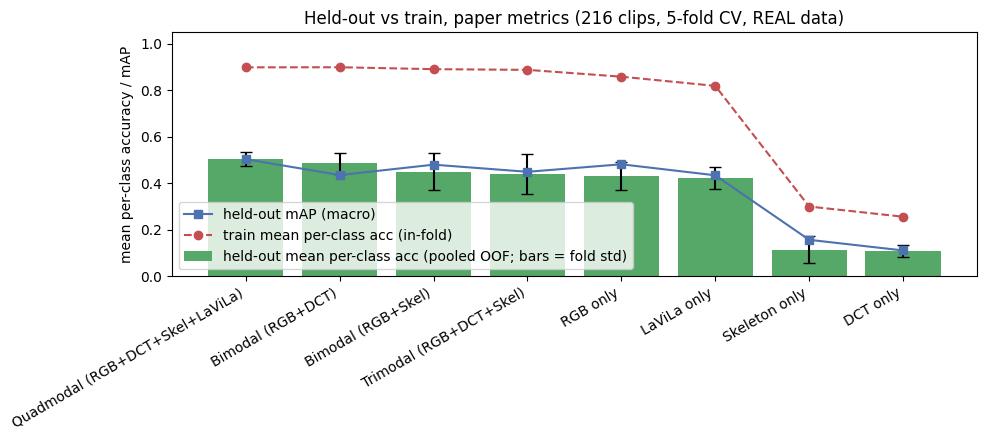

Largest train-vs-held-out gap: Trimodal (RGB+DCT+Skel) (+0.45).  A gap near 0 means little overfitting; a large gap means the head memorises training clips -- prefer variants with a small gap.
Reference (paper, BBSI, multilabel, 3 views, 2.87M frames): trimodal MAP 0.52 val / 0.62 test -- NOT directly comparable.


In [14]:
rows = []
for vname in VARIANTS:
    p = OOF[vname]
    fd = fold_df[fold_df.model == vname]
    h_mpca = mean_per_class_acc(p, y_all)                    # PAPER multiclass metric: mean per-class accuracy
    rows.append({
        "model": vname,
        "heldout_mpca": h_mpca,
        "heldout_mAP": macro_map(p, y_all),                  # PAPER MAP: per-class AP, macro-averaged
        "overall_acc (ref)": float((p.argmax(1) == y_all).mean()),
        "fold_mpca_mean": fd.test_mpca.mean(), "fold_mpca_std": fd.test_mpca.std(ddof=0),
        "fold_mAP_mean": fd.test_mAP.mean(),
        "train_mpca": fd.train_mpca.mean(),
        "overfit_gap": fd.train_mpca.mean() - h_mpca,
        "median_best_epoch": int(np.median(BEST_EPOCHS[vname])),
    })
results_df = pd.DataFrame(rows).sort_values(["heldout_mpca", "heldout_mAP"], ascending=[False, False]).reset_index(drop=True)
print(f"Pooled out-of-fold results ({N} clips, {K}-fold subject-grouped CV, {DATA_TAG} data) -- paper metrics:")
print("  heldout_mpca = mean per-class accuracy | heldout_mAP = macro-averaged per-class AP | overall_acc = reference only")
display(results_df.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(results_df["model"], results_df["heldout_mpca"], yerr=results_df["fold_mpca_std"], capsize=4, color="#55A868",
       label="held-out mean per-class acc (pooled OOF; bars = fold std)")
ax.plot(results_df["model"], results_df["heldout_mAP"], "s-", color="#4C72B0", label="held-out mAP (macro)")
ax.plot(results_df["model"], results_df["train_mpca"], "o--", color="#C44E52", label="train mean per-class acc (in-fold)")
ax.set_ylim(0, 1.05); ax.set_ylabel("mean per-class accuracy / mAP")
ax.set_title(f"Held-out vs train, paper metrics ({N} clips, {K}-fold CV, {DATA_TAG} data)")
ax.legend(loc="lower left"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

worst = results_df.iloc[results_df["overfit_gap"].idxmax()]
print(f"Largest train-vs-held-out gap: {worst['model']} ({worst['overfit_gap']:+.2f}).  A gap near 0 means little overfitting; "
      "a large gap means the head memorises training clips -- prefer variants with a small gap.")
print("Reference (paper, BBSI, multilabel, 3 views, 2.87M frames): trimodal MAP 0.52 val / 0.62 test -- NOT directly comparable.")


## 10. Best model -- confusion matrix and per-class report (pooled out-of-fold predictions)

Selected variant: Quadmodal (RGB+DCT+Skel+LaViLa) | mean per-class acc 0.505 | mAP 0.503 | rank by mean per-class acc: 1/8


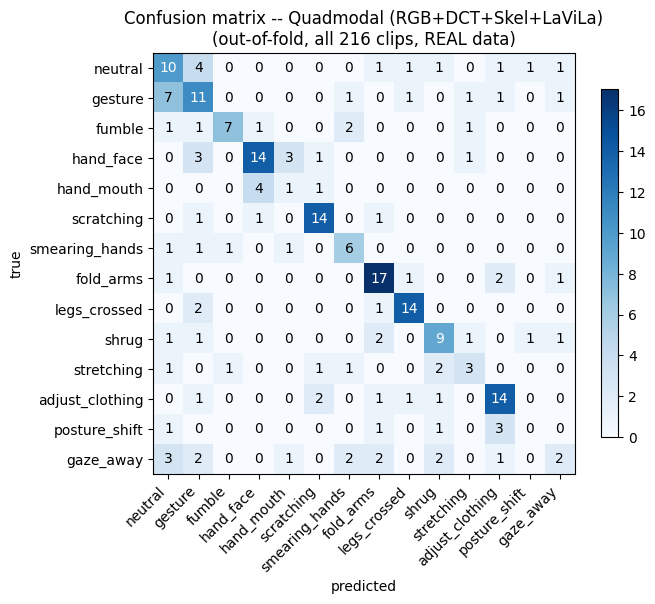

Variant: Quadmodal (RGB+DCT+Skel+LaViLa)

                 precision    recall  f1-score   support

        neutral       0.38      0.50      0.43        20
        gesture       0.41      0.48      0.44        23
         fumble       0.78      0.54      0.64        13
      hand_face       0.70      0.64      0.67        22
     hand_mouth       0.17      0.17      0.17         6
     scratching       0.74      0.82      0.78        17
 smearing_hands       0.50      0.60      0.55        10
      fold_arms       0.65      0.77      0.71        22
   legs_crossed       0.78      0.82      0.80        17
          shrug       0.56      0.56      0.56        16
     stretching       0.43      0.33      0.38         9
adjust_clothing       0.64      0.70      0.67        20
  posture_shift       0.00      0.00      0.00         6
      gaze_away       0.33      0.13      0.19        15

       accuracy                           0.56       216
      macro avg       0.50      0.50      0.

,fold,train_mpca,test_mpca,test_mAP,train_acc,test_acc,best_epoch
7,1,0.899,0.569,0.647,0.897,0.634,11
15,2,0.906,0.533,0.682,0.908,0.535,13
23,3,0.869,0.496,0.570,0.889,0.578,18
31,4,0.888,0.529,0.554,0.919,0.523,10
39,5,0.933,0.483,0.559,0.925,0.558,18



Class-wise metrics of the best variant (Quadmodal (RGB+DCT+Skel+LaViLa)):


,support,top1_recognition_rate,AP
neutral,20,0.500,0.346
gesture,23,0.478,0.308
fumble,13,0.538,0.584
hand_face,22,0.636,0.599
hand_mouth,6,0.167,0.214
scratching,17,0.824,0.827
smearing_hands,10,0.600,0.508
fold_arms,22,0.773,0.759
legs_crossed,17,0.824,0.900
shrug,16,0.562,0.477


Mean per-class accuracy (paper multiclass metric): 0.505
MAP (macro-averaged AP, paper):                     0.503

Class-wise average precision for every variant (pooled out-of-fold):


,Quadmodal (RGB+DCT+Skel+LaViLa),Bimodal (RGB+DCT),Bimodal (RGB+Skel),Trimodal (RGB+DCT+Skel),RGB only,LaViLa only,Skeleton only,DCT only
neutral,0.346,0.356,0.396,0.307,0.373,0.312,0.153,0.117
gesture,0.308,0.277,0.290,0.274,0.368,0.322,0.105,0.158
fumble,0.584,0.542,0.575,0.377,0.542,0.424,0.115,0.056
hand_face,0.599,0.550,0.540,0.586,0.474,0.486,0.103,0.075
hand_mouth,0.214,0.111,0.154,0.208,0.136,0.117,0.160,0.049
scratching,0.827,0.594,0.656,0.680,0.722,0.653,0.262,0.150
smearing_hands,0.508,0.416,0.582,0.580,0.606,0.315,0.089,0.046
fold_arms,0.759,0.591,0.531,0.603,0.564,0.739,0.146,0.219
legs_crossed,0.900,0.876,0.925,0.856,0.927,0.857,0.620,0.137
shrug,0.477,0.429,0.531,0.379,0.542,0.448,0.118,0.098


Class-wise top-1 recognition rate for every variant (pooled out-of-fold):


,Quadmodal (RGB+DCT+Skel+LaViLa),Bimodal (RGB+DCT),Bimodal (RGB+Skel),Trimodal (RGB+DCT+Skel),RGB only,LaViLa only,Skeleton only,DCT only
neutral,0.500,0.400,0.450,0.250,0.450,0.300,0.250,0.150
gesture,0.478,0.348,0.217,0.435,0.348,0.565,0.043,0.304
fumble,0.538,0.538,0.462,0.462,0.615,0.308,0.077,0.000
hand_face,0.636,0.818,0.591,0.682,0.545,0.727,0.045,0.045
hand_mouth,0.167,0.167,0.000,0.167,0.167,0.000,0.000,0.000
scratching,0.824,0.588,0.588,0.588,0.529,0.588,0.235,0.294
smearing_hands,0.600,0.500,0.900,0.700,0.400,0.400,0.000,0.000
fold_arms,0.773,0.545,0.591,0.455,0.500,0.682,0.182,0.318
legs_crossed,0.824,0.824,0.824,0.765,0.765,0.765,0.588,0.000
shrug,0.562,0.438,0.375,0.312,0.625,0.562,0.062,0.062


In [15]:
if REPORT_VARIANT is not None and REPORT_VARIANT not in VARIANTS:
    print(f"WARNING: REPORT_VARIANT={REPORT_VARIANT!r} is not available in this run (LaViLa missing?) -> using the top-ranked variant.")
best_name = REPORT_VARIANT if (REPORT_VARIANT in VARIANTS) else results_df.iloc[0]["model"]
sel = results_df[results_df.model == best_name].iloc[0]          # metrics row of the selected variant
print(f"Selected variant: {best_name} | mean per-class acc {sel['heldout_mpca']:.3f} | mAP {sel['heldout_mAP']:.3f} | "
      f"rank by mean per-class acc: {int(results_df.index[results_df.model == best_name][0]) + 1}/{len(results_df)}")
p_best = OOF[best_name]
all_preds, all_labels = p_best.argmax(1), y_all
present_classes = sorted(set(all_labels.tolist()) | set(all_preds.tolist()))
present_names = [CLASSES[i] for i in present_classes]
cm = confusion_matrix(all_labels, all_preds, labels=present_classes)

fig_cm, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(present_names))); ax.set_xticklabels(present_names, rotation=45, ha="right")
ax.set_yticks(range(len(present_names))); ax.set_yticklabels(present_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Confusion matrix -- {best_name}\n(out-of-fold, all {N} clips, {DATA_TAG} data)")
for i in range(len(present_names)):
    for j in range(len(present_names)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig_cm.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
print(f"Variant: {best_name}\n")
print(classification_report(all_labels, all_preds, labels=present_classes, target_names=present_names, zero_division=0))
print("Per-fold accuracy of the best variant:")
display(fold_df[fold_df.model == best_name][["fold", "train_mpca", "test_mpca", "test_mAP", "train_acc", "test_acc", "best_epoch"]].round(3))
# ---- paper-style class-wise metrics (cf. paper Table II: class-wise AP per method) --------------------------
pc_df = pd.DataFrame({"support": np.bincount(y_all, minlength=NUM_CLASSES),
                      "top1_recognition_rate": per_class_acc(p_best, y_all),
                      "AP": per_class_ap(p_best, y_all)}, index=CLASSES)
print(f"\nClass-wise metrics of the best variant ({best_name}):")
display(pc_df.round(3))
print(f"Mean per-class accuracy (paper multiclass metric): {pc_df.top1_recognition_rate.mean():.3f}")
print(f"MAP (macro-averaged AP, paper):                     {pc_df.AP.mean():.3f}")

classwise_ap_df = pd.DataFrame({v: per_class_ap(OOF[v], y_all) for v in results_df["model"]}, index=CLASSES)
classwise_acc_df = pd.DataFrame({v: per_class_acc(OOF[v], y_all) for v in results_df["model"]}, index=CLASSES)
classwise_ap_df.loc["MAP (macro)"] = classwise_ap_df.mean()
classwise_acc_df.loc["Mean per-class acc"] = classwise_acc_df.mean()
print("\nClass-wise average precision for every variant (pooled out-of-fold):")
display(classwise_ap_df.round(3))
print("Class-wise top-1 recognition rate for every variant (pooled out-of-fold):")
display(classwise_acc_df.round(3))


## 11. Modality contribution (ablation substitute for the paper's attention scores, §V)

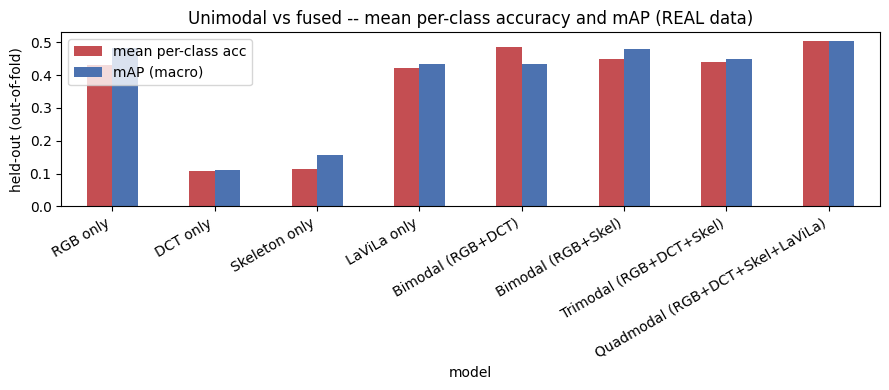

Best unimodal: RGB only (mean per-class acc 43.1%, mAP 0.481)
Best fused:    Quadmodal (RGB+DCT+Skel+LaViLa) (mean per-class acc 50.5%, mAP 0.503)
Fusion delta:  mean per-class acc +7.4% | mAP +0.022


In [16]:
unimodal_names = ["RGB only", "DCT only", "Skeleton only"] + (["LaViLa only"] if LAVILA_AVAILABLE else [])
fused_names = ["Bimodal (RGB+DCT)", "Bimodal (RGB+Skel)", "Trimodal (RGB+DCT+Skel)"] + \
              (["Quadmodal (RGB+DCT+Skel+LaViLa)"] if LAVILA_AVAILABLE else [])
order = unimodal_names + fused_names
contrib = results_df.set_index("model")[["heldout_mpca", "heldout_mAP"]].reindex(order)
fig, ax = plt.subplots(figsize=(9, 4))
contrib.plot(kind="bar", ax=ax, color=["#C44E52", "#4C72B0"])
ax.set_ylabel("held-out (out-of-fold)")
ax.set_title(f"Unimodal vs fused -- mean per-class accuracy and mAP ({DATA_TAG} data)")
ax.legend(["mean per-class acc", "mAP (macro)"])
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

bu = results_df[results_df.model.isin(unimodal_names)].iloc[0]
bf = results_df[results_df.model.isin(fused_names)].iloc[0]
print(f"Best unimodal: {bu['model']} (mean per-class acc {bu['heldout_mpca']:.1%}, mAP {bu['heldout_mAP']:.3f})")
print(f"Best fused:    {bf['model']} (mean per-class acc {bf['heldout_mpca']:.1%}, mAP {bf['heldout_mAP']:.3f})")
print(f"Fusion delta:  mean per-class acc {bf['heldout_mpca'] - bu['heldout_mpca']:+.1%} | mAP {bf['heldout_mAP'] - bu['heldout_mAP']:+.3f}")


## 11b. Paper-style summary (relative improvement over baseline, ANOVA)

In [17]:
# ---- Paper-style summary (Table I / Table II / ANOVA of §IV-D1), computed on the pooled out-of-fold predictions ----
from scipy import stats as sps
base_name = "RGB only"                                    # baseline = Video-Swin RGB (paper baseline [11] is Video Swin on RGB)
base = results_df.set_index("model").loc[base_name]
tab = results_df.set_index("model")[["heldout_mAP", "heldout_mpca"]].copy()
tab["mAP_rel_improvement_vs_baseline_%"] = 100 * (tab["heldout_mAP"] - base["heldout_mAP"]) / base["heldout_mAP"]
tab["mpca_rel_improvement_vs_baseline_%"] = 100 * (tab["heldout_mpca"] - base["heldout_mpca"]) / base["heldout_mpca"]
print(f"Relative improvement over the baseline ({base_name}), as the paper reports for MAP:")
display(tab.round(3))

# one-way ANOVA across the behaviour classes (paper: 'one-way ANOVA across the 14 behavioral classes'):
# groups = classes, samples = that class's per-fold AP of the selected variant
groups_ap = []
for c in range(NUM_CLASSES):
    vals = []
    for _, te in FOLDS:
        if (y_all[te] == c).any():
            vals.append(average_precision_score((y_all[te] == c).astype(int), OOF[best_name][te, c]))
    if len(vals) >= 2:
        groups_ap.append(vals)
if len(groups_ap) >= 2:
    f_stat, p_val = sps.f_oneway(*groups_ap)
    print(f"One-way ANOVA across {len(groups_ap)} classes ({best_name}, per-fold class AP): F = {f_stat:.2f}, p = {p_val:.4g} "
          f"({'significant' if p_val < 0.05 else 'not significant'} at p < 0.05)")


Relative improvement over the baseline (RGB only), as the paper reports for MAP:


,heldout_mAP,heldout_mpca,mAP_rel_improvement_vs_baseline_%,mpca_rel_improvement_vs_baseline_%
model,,,,
Quadmodal (RGB+DCT+Skel+LaViLa),0.503,0.505,4.514,17.053
Bimodal (RGB+DCT),0.435,0.486,-9.647,12.682
Bimodal (RGB+Skel),0.480,0.449,-0.346,4.099
Trimodal (RGB+DCT+Skel),0.449,0.439,-6.730,1.809
RGB only,0.481,0.431,0.000,0.000
LaViLa only,0.434,0.423,-9.865,-1.974
Skeleton only,0.156,0.113,-67.593,-73.775
DCT only,0.110,0.108,-77.103,-75.030


One-way ANOVA across 14 classes (Quadmodal (RGB+DCT+Skel+LaViLa), per-fold class AP): F = 2.74, p = 0.005015 (significant at p < 0.05)


## 12. Final model trained on ALL clips

The deployable model uses every clip: Swin-B RGB/DCT are fine-tuned on all clips (same fixed recipe), then the best
variant's head is trained on all clips for the median best epoch found in cross-validation. **Its expected accuracy is the
cross-validated number from Section 9** — there is no held-out data left, so its own training accuracy is not a valid
estimate of generalisation.

In [18]:
FINAL = {}
if FINAL_FIT_ALL:
    t0 = time.time()
    all_idx = np.arange(N)
    set_seed(SEED)
    print(f"Training final model on ALL {N} clips (variant: {best_name}) ...")
    sw = swin_stage(all_idx, "final")
    feats_all, stats_all = build_feats(sw["rgb"][0], sw["dct"][0], all_idx)
    final_epochs = max(10, int(np.median(BEST_EPOCHS[best_name])))
    final_head, _ = train_head(VARIANTS[best_name], feats_all, all_idx, es_idx=None, fixed_epochs=final_epochs)
    p_fin, y_fin = predict_probs(final_head, feats_all, all_idx)
    print(f"Head epochs: {final_epochs} (median of CV best epochs).")
    print(f"Final model on its own training clips: mean per-class accuracy {mean_per_class_acc(p_fin, y_fin):.1%}, "
          f"mAP {macro_map(p_fin, y_fin):.3f}  (NOT a generalisation estimate)")
    print(f"Expected real-world performance ~ cross-validated held-out metrics (pooled out-of-fold, {N} clips): "
          f"mean per-class accuracy {sel['heldout_mpca']:.1%}, mAP {sel['heldout_mAP']:.3f}")
    FINAL = {"head_state": final_head.state_dict(), "rgb_finetuned_params": sw["rgb"][1], "dct_finetuned_params": sw["dct"][1],
             "stats": {k: (v[0].cpu(), v[1].cpu()) for k, v in stats_all.items()}, "epochs": final_epochs}
    del sw
    print(f"Final fit done in {(time.time() - t0) / 60:.1f} min")
else:
    print("FINAL_FIT_ALL is False -- skipping the all-clips model.")

Training final model on ALL 216 clips (variant: Quadmodal (RGB+DCT+Skel+LaViLa)) ...
  [final-RGB] fine-tuning (last_stage): 25.4M backbone params, 216 train clips, 10 epochs
    epoch  1/10 | train loss 2.684 | train acc 0.13
    epoch  2/10 | train loss 1.918 | train acc 0.42
    epoch  3/10 | train loss 1.383 | train acc 0.67
    epoch  4/10 | train loss 1.144 | train acc 0.76
    epoch  5/10 | train loss 1.019 | train acc 0.83
    epoch  6/10 | train loss 0.894 | train acc 0.91
    epoch  7/10 | train loss 0.861 | train acc 0.91
    epoch  8/10 | train loss 0.839 | train acc 0.92
    epoch  9/10 | train loss 0.813 | train acc 0.94
    epoch 10/10 | train loss 0.807 | train acc 0.95
  [final-DCT] fine-tuning (last_stage): 25.4M backbone params, 216 train clips, 10 epochs
    epoch  1/10 | train loss 2.708 | train acc 0.06
    epoch  2/10 | train loss 2.695 | train acc 0.08
    epoch  3/10 | train loss 2.637 | train acc 0.09
    epoch  4/10 | train loss 2.588 | train acc 0.09
    epo

## 13. Save everything

Under `WORK_DIR` (`/kaggle/working`). Files are prefixed `SYNTHETIC_` if synthetic data was used.
- `cv_results.csv` (pooled out-of-fold table, paper metrics), `cv_fold_results.csv` (per fold), `oof_predictions.csv`,
  `cv_classwise_AP.csv` and `cv_classwise_acc.csv` (class-wise tables, cf. paper Table II)
- `confusion_matrix.png`
- `final_model_<variant>.pt` — head weights, standardisation stats, and the fine-tuned Swin parameters (last stage + norm, fp16).
  Reload by building the same pretrained Swin-B and loading those tensors on top.

In [19]:
prefix = "SYNTHETIC_" if USING_SYNTHETIC else ""
results_df.to_csv(os.path.join(WORK_DIR, f"{prefix}cv_results.csv"), index=False)
fold_df.to_csv(os.path.join(WORK_DIR, f"{prefix}cv_fold_results.csv"), index=False)

oof = annotations[["clip_id", "class_name"]].copy()
for vname in VARIANTS:
    oof[f"pred_{re.sub('[^A-Za-z0-9]+', '_', vname).strip('_')}"] = [CLASSES[i] for i in OOF[vname].argmax(1)]
oof.to_csv(os.path.join(WORK_DIR, f"{prefix}oof_predictions.csv"), index=False)
classwise_ap_df.to_csv(os.path.join(WORK_DIR, f"{prefix}cv_classwise_AP.csv"))
classwise_acc_df.to_csv(os.path.join(WORK_DIR, f"{prefix}cv_classwise_acc.csv"))

cm_path = os.path.join(WORK_DIR, f"{prefix}confusion_matrix.png")
fig_cm.savefig(cm_path, dpi=150, bbox_inches="tight")

saved = [f"{prefix}cv_results.csv", f"{prefix}cv_fold_results.csv", f"{prefix}oof_predictions.csv",
         f"{prefix}cv_classwise_AP.csv", f"{prefix}cv_classwise_acc.csv", f"{prefix}confusion_matrix.png"]
if FINAL:
    safe = re.sub(r"[^A-Za-z0-9_]+", "_", best_name).strip("_")
    fp = os.path.join(WORK_DIR, f"{prefix}final_model_{safe}.pt")
    torch.save({**FINAL, "variant": best_name, "modalities": VARIANTS[best_name], "classes": CLASSES,
                "backbone": BACKBONE_NAME, "feat_dims": FEAT_DIMS, "stream_dims": STREAM_DIMS,
                "cv_mean_per_class_acc": float(sel["heldout_mpca"]),
                "cv_mAP": float(sel["heldout_mAP"]),
                "cv_overall_acc": float(sel["overall_acc (ref)"]), "data": DATA_TAG}, fp)
    saved.append(os.path.basename(fp))

print("Saved in", WORK_DIR)
for s_ in saved:
    print("  ", s_)
print(f"\nSelected variant: {best_name} -- held-out (out-of-fold) mean per-class accuracy {sel['heldout_mpca']:.1%}, "
      f"MAP {sel['heldout_mAP']:.3f} (overall acc {sel['overall_acc (ref)']:.1%}, reference only), "
      f"on {N} clips ({DATA_TAG} data, {K}-fold subject-grouped CV).")
print(f"LaViLa was {'included' if LAVILA_AVAILABLE else 'not available in this run'}.")
if USING_SYNTHETIC:
    print("\n*** SYNTHETIC data: these numbers are meaningless. Attach your preprocessed_dataset.zip and re-run. ***")

Saved in /kaggle/working
   cv_results.csv
   cv_fold_results.csv
   oof_predictions.csv
   cv_classwise_AP.csv
   cv_classwise_acc.csv
   confusion_matrix.png
   final_model_Quadmodal_RGB_DCT_Skel_LaViLa.pt

Selected variant: Quadmodal (RGB+DCT+Skel+LaViLa) -- held-out (out-of-fold) mean per-class accuracy 50.5%, MAP 0.503 (overall acc 56.5%, reference only), on 216 clips (REAL data, 5-fold subject-grouped CV).
LaViLa was included.
